# Token-Adaptive FFN for Vision Transformers
### Adaptive Computation Allocation for Efficient Vision Transformer Feedforward Networks
**Aakarsh Devulapally

This notebook is the complete, reproducible implementation of the project proposed in the presentation, written to the standard needed for an IEEE-style paper. Every number, table and figure is **produced by running the code** — nothing is hard-coded.

| Slide | Proposal | Where it is implemented |
|---|---|---|
| 3 – FFN bottleneck | FFN dominates ViT cost | §3 cost model + §6 latency benchmark |
| 4 – RePaViT | channel-idle FFN + structural re-parameterisation | `RePaFFN` → `CondensedFFN` (exactness verified in §3) |
| 5/8 – gap & comparison | fixed vs token-level, input-dependent, multi-level | `AdaptiveFFN` |
| 6/7 – approach | estimator → Full / Reduced / Lightweight tiers, shapes + residuals preserved | `AdaptiveFFN` (3 tiers, residual stream untouched) |
| 9 – research question | better accuracy–efficiency trade-off, Pareto shift | §7 Pareto figure, §8 statistics |
| 10 – metrics (8) | Top-1, FLOPs, latency, throughput, GPU memory, params, avg compute / input, compute distribution across tokens | §5–§9 |
| 11 – workflow | baselines → estimator → tiered FFN → train allocation → evaluate | §2–§9 in order |
| 12 – caveats | cheap estimator, preserved shapes, **fair comparison, no unsupported claims** | iso-FLOPs control, same recipe for every model, estimator cost *included* in FLOPs |

**Scientific design choices that make the comparison defensible**
1. **One training recipe for all models** (same data pipeline, optimiser, epochs, seeds). RePaViT is *re-implemented and re-trained* here, so the comparison is apples-to-apples; paper-reported numbers are never mixed into our tables.
2. **Matched FFN budgets.** RePaViT with idle-ratio θ has FFN cost (9−8θ)/8 of a full FFN, so the adaptive targets ρ ∈ {0.375, 0.625, 0.875} are chosen to match θ ∈ {0.75, 0.5, 0.25} exactly. A **static narrow-FFN** control at the same ρ isolates *whether adaptivity itself* (not just "less compute") helps.
3. **The estimator's own cost is counted** (slide 12's first challenge) in every FLOP figure, and FLOPs are cross-checked against PyTorch's `FlopCounterMode` on the *real sparse-dispatch execution*.
4. **Real latency, not just FLOPs.** Inference uses true gather → small-matmul → scatter dispatch; latency / throughput / peak memory are measured on the GPU for fp32 and fp16 and reported honestly even where they lag the FLOP reduction.
5. **Rigour:** held-out validation split (no test-set model selection, last-epoch weights reported), multiple seeds, Welch tests, exact McNemar tests, bootstrap CIs, eval-time routing-policy ablations (random / attention-heuristic / inverted router) that prove whether the *learned* estimator matters.

## 0 · How to run on Kaggle
1. **Settings → Accelerator → GPU T4 ×2** (or P100) and **Internet → On** (needed once to download CIFAR; alternatively *Add Input* → any CIFAR-100 dataset).
2. Run the notebook top-to-bottom with `PROFILE = "smoke"` (≈2 min) to confirm the environment, then `"fast"` (a first look at the Pareto trend), then `"paper"` for publication numbers.
3. **Everything is resumable.** Finished runs are cached as `result.json`; interrupted runs resume from their last checkpoint. If a 9–12 h session is not enough for `paper`, just re-run — or *Save Version* and attach the previous output as an input and set `RESUME_FROM` (§1).
4. With **2 GPUs** the notebook automatically trains two models in parallel (one worker process per GPU).

> **Honest time budgeting.** I could only smoke-test this code on CPU, so I cannot promise GPU timings. Run `fast` first and read the per-epoch times it prints, then scale `epochs`/`seeds` to your session limit.

In [ ]:
# This script finds the dataset you uploaded earlier (even if the UI crashed)
import os
from pathlib import Path

print("Searching for your uploaded zip...")
found = False
for p in Path("/kaggle/input").rglob("*"):
    if p.is_file() and ("aff" in p.name.lower() or "result" in p.name.lower()) and p.suffix == ".zip":
        print("Found:", p)
        found = True

if not found:
    print("❌ Could not find the zip in /kaggle/input.")
    print("Please attach the 338MB zip as an input to this notebook.")

Searching for your uploaded zip...
❌ Could not find the zip in /kaggle/input.
Please attach the 338MB zip as an input to this notebook.


In [ ]:
# ============================== 1 · SETUP =====================================================
import os, sys, json, time, math, glob, copy, shutil, platform, subprocess, textwrap, warnings, itertools
from dataclasses import asdict
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import stats
try:
    from IPython.display import display, Markdown
except Exception:
    display = print
    Markdown = lambda s: s
warnings.filterwarnings("ignore")

WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd() / "aff_work"
WORK.mkdir(parents=True, exist_ok=True)
os.chdir(WORK)
if str(WORK) not in sys.path:
    sys.path.insert(0, str(WORK))

print(f"python {platform.python_version()} | torch {torch.__version__} | cuda={torch.cuda.is_available()} | gpus={torch.cuda.device_count()}")
for i in range(torch.cuda.device_count()):
    p = torch.cuda.get_device_properties(i)
    print(f"  GPU{i}: {p.name}  {p.total_memory/2**30:.1f} GB")

python 3.13.16 | torch 2.11.0+cu130 | cuda=True | gpus=2
  GPU0: Tesla T4  14.6 GB
  GPU1: Tesla T4  14.6 GB


In [ ]:
%%writefile affvit.py
"""
affvit.py -- Token-Adaptive FFN for Vision Transformers (research code, v2, IEEE submission)
============================================================================================
v2 changes:
  * per_layer_only router -> ablates per-token from per-layer adaptivity (B2)
  * train_cost_last_epoch + test_route_entropy -> train/test budget gap (B9, B3)
  * flop_breakdown -> FFN-vs-attention claim for the intro (D1)
  * time_breakdown -> wall-clock dispatch overhead (D3)
  * routing_stability -> cross-seed routing agreement (B4)
  * torch >= 2.6 compat: weights_only for ckpt / model (A1)
  * cudnn deterministic in set_seed -> reproducibility (E1)
  * benchmark: reset peak memory after warmup (A7)
  * dataset_hash in every result.json (E4)
  * make_specs: abl_perlayer_static, abl_no_budget, abl_lam5, abl_lam500, abl_heavy_router
"""
from __future__ import annotations
import os, sys, json, math, time, copy, random, argparse, traceback, hashlib
from dataclasses import dataclass, asdict
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import precision_recall_fscore_support


# 1. Config
@dataclass
class Cfg:
    dataset: str = "cifar100"
    data_root: str = "/kaggle/working/data"
    val_size: int = 5000
    train_subset: int = 0
    num_classes: int = 100
    img_size: int = 32
    patch: int = 4
    in_ch: int = 3
    dim: int = 192
    depth: int = 12
    heads: int = 3
    mlp_ratio: float = 4.0
    drop_path: float = 0.1
    epochs: int = 100
    bs: int = 256
    lr: float = 1e-3
    wd: float = 0.05
    warmup: int = 5
    label_smooth: float = 0.1
    mix_prob: float = 0.8
    clip: float = 1.0
    amp: bool = True
    lam_budget: float = 50.0
    tau0: float = 1.5
    tau1: float = 0.5
    lam_ent: float = 0.0     # v2: entropy penalty removed (was 0.01)
    lam_aux: float = 0.5     # v2: weight of auxiliary deep-supervision loss (0 disables aux heads)
    noise_end_frac: float = 0.6
    kd_alpha: float = 0.5
    kd_T: float = 2.0
    out_dir: str = "/kaggle/working/aff_results"

    def to_json(self, path): Path(path).write_text(json.dumps(asdict(self), indent=2))
    @staticmethod
    def from_json(path): return Cfg(**json.loads(Path(path).read_text()))


def set_seed(seed: int):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


# 2. Data
def _find_cifar_root(name):
    folder = {"cifar100": "cifar-100-python", "cifar10": "cifar-10-batches-py"}[name]
    base = "/kaggle/input"
    if not os.path.isdir(base): return None
    for dp, dns, _ in os.walk(base):
        if os.path.basename(dp) == folder: return os.path.dirname(dp)
        if dp.count(os.sep) - base.count(os.sep) > 4: dns[:] = []
    return None


def load_arrays(cfg):
    if cfg.dataset == "synthetic":
        g = np.random.RandomState(0); n = cfg.train_subset or 1024
        xtr = g.randint(0, 256, (n + 256, 32, 32, 3), dtype=np.uint8); ytr = g.randint(0, cfg.num_classes, n + 256)
        xte = g.randint(0, 256, (256, 32, 32, 3), dtype=np.uint8); yte = g.randint(0, cfg.num_classes, 256)
        return xtr, ytr, xte, yte
    import torchvision
    C = torchvision.datasets.CIFAR100 if cfg.dataset == "cifar100" else torchvision.datasets.CIFAR10
    try:
        tr = C(cfg.data_root, train=True, download=True); te = C(cfg.data_root, train=False, download=True)
    except Exception as e:
        alt = _find_cifar_root(cfg.dataset)
        if alt is None: raise RuntimeError("Could not download CIFAR.") from e
        tr = C(alt, train=True, download=False); te = C(alt, train=False, download=False)
    return tr.data, np.array(tr.targets), te.data, np.array(te.targets)


class GPUData:
    def __init__(self, cfg, device):
        xtr, ytr, xte, yte = load_arrays(cfg)
        perm = np.random.RandomState(1234).permutation(len(xtr))
        nv = min(cfg.val_size, len(xtr) // 5)
        vi, ti = perm[:nv], perm[nv:]
        if cfg.train_subset: ti = ti[: cfg.train_subset]
        T = lambda a: torch.from_numpy(np.ascontiguousarray(a)).permute(0, 3, 1, 2).contiguous().to(device)
        Y = lambda a: torch.from_numpy(np.asarray(a)).long().to(device)
        self.xtr, self.ytr = T(xtr[ti]), Y(ytr[ti])
        self.xva, self.yva = T(xtr[vi]), Y(ytr[vi])
        self.xte, self.yte = T(xte), Y(yte)
        f = self.xtr.float() / 255
        self.mean = f.mean((0, 2, 3)).view(1, 3, 1, 1)
        self.std = f.std((0, 2, 3)).view(1, 3, 1, 1)
        self.device = device
        self.num_classes = int(max(self.ytr.max(), self.yte.max()).item()) + 1
        h = hashlib.sha256()
        h.update(f"{cfg.dataset}|{len(xtr)}|{len(self.xtr)}|{len(self.xva)}|{len(self.xte)}|{cfg.val_size}".encode())
        self.dataset_hash = h.hexdigest()[:16]

    def norm(self, xb_u8): return (xb_u8.float() / 255 - self.mean) / self.std


def rand_crop_flip(x, pad=4):
    B, C, H, W = x.shape
    xp = F.pad(x, (pad,) * 4, mode="reflect")
    dy = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    dx = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    ar = torch.arange(H, device=x.device)
    iy = dy[:, None] + ar[None]; ix = dx[:, None] + ar[None]
    out = xp[torch.arange(B, device=x.device)[:, None, None], :, iy[:, :, None], ix[:, None, :]]
    out = out.permute(0, 3, 1, 2)
    flip = torch.rand(B, device=x.device) < 0.5
    return torch.where(flip[:, None, None, None], out.flip(3), out).contiguous()


def mix_batch(x, y, nc, smooth, prob):
    yo = F.one_hot(y, nc).float() * (1 - smooth) + smooth / nc
    if np.random.rand() > prob: return x, yo
    B, _, H, W = x.shape
    perm = torch.randperm(B, device=x.device)
    if np.random.rand() < 0.5:
        lam = float(np.random.beta(0.8, 0.8)); x = lam * x + (1 - lam) * x[perm]
    else:
        lam = float(np.random.beta(1.0, 1.0))
        rh, rw = int(H * math.sqrt(1 - lam)), int(W * math.sqrt(1 - lam))
        cy, cx = np.random.randint(H), np.random.randint(W)
        y1, y2 = max(cy - rh // 2, 0), min(cy + rh // 2, H)
        x1, x2 = max(cx - rw // 2, 0), min(cx + rw // 2, W)
        x = x.clone(); x[:, :, y1:y2, x1:x2] = x[perm][:, :, y1:y2, x1:x2]
        lam = 1 - (y2 - y1) * (x2 - x1) / (H * W)
    return x, lam * yo + (1 - lam) * yo[perm]


# 3. Model
class DropPath(nn.Module):
    def __init__(self, p): super().__init__(); self.p = p
    def forward(self, x):
        if self.p == 0.0 or not self.training: return x
        keep = 1 - self.p
        return x * x.new_empty(x.shape[0], 1, 1).bernoulli_(keep) / keep


class Attention(nn.Module):
    def __init__(self, dim, heads):
        super().__init__()
        self.h, self.dim = heads, dim
        self.scale = (dim // heads) ** -0.5
        self.qkv = nn.Linear(dim, dim * 3); self.proj = nn.Linear(dim, dim)
    def forward(self, x, want_cls_attn=False):
        B, N, C = x.shape
        q, k, v = self.qkv(x).reshape(B, N, 3, self.h, C // self.h).permute(2, 0, 3, 1, 4)
        o = F.scaled_dot_product_attention(q, k, v).transpose(1, 2).reshape(B, N, C)
        ca = None
        if want_cls_attn:
            with torch.no_grad():
                a = (q[:, :, :1] @ k.transpose(-2, -1)) * self.scale
                ca = a.float().softmax(-1).mean(1).squeeze(1)
        return self.proj(o), ca


class FFNBase(nn.Module):
    def wants_attn(self): return False


class DenseFFN(FFNBase):
    def __init__(self, dim, hidden):
        super().__init__(); self.dim, self.hidden = dim, hidden
        self.fc1, self.fc2 = nn.Linear(dim, hidden), nn.Linear(hidden, dim)
        self.macs_tok = 2 * dim * hidden
    def forward(self, x, cls_attn=None): return self.fc2(F.gelu(self.fc1(x)))


class CondensedFFN(FFNBase):
    def __init__(self, dim, n_act):
        super().__init__(); self.dim, self.n_act = dim, n_act
        self.fc1, self.fc2 = nn.Linear(dim, n_act), nn.Linear(n_act, dim, bias=False)
        self.lin = nn.Linear(dim, dim); self.macs_tok = 2 * dim * n_act + dim * dim
    def forward(self, x, cls_attn=None): return self.fc2(F.gelu(self.fc1(x))) + self.lin(x)


class RePaFFN(FFNBase):
    def __init__(self, dim, hidden, theta):
        super().__init__()
        self.dim, self.hidden = dim, hidden
        self.n_idle = int(round(theta * hidden)); self.n_act = hidden - self.n_idle
        assert self.n_act > 0
        self.fc1, self.fc2 = nn.Linear(dim, hidden), nn.Linear(hidden, dim)
        self.macs_tok = 2 * dim * hidden
    def forward(self, x, cls_attn=None):
        h = self.fc1(x)
        h = torch.cat([F.gelu(h[..., : self.n_act]), h[..., self.n_act:]], dim=-1)
        return self.fc2(h)
    @torch.no_grad()
    def reparameterize(self):
        na = self.n_act
        W1, b1, W2, b2 = (self.fc1.weight.double(), self.fc1.bias.double(),
                          self.fc2.weight.double(), self.fc2.bias.double())
        m = CondensedFFN(self.dim, na).to(self.fc1.weight.device)
        m.fc1.weight.copy_(W1[:na]); m.fc1.bias.copy_(b1[:na]); m.fc2.weight.copy_(W2[:, :na])
        m.lin.weight.copy_(W2[:, na:] @ W1[na:]); m.lin.bias.copy_(W2[:, na:] @ b1[na:] + b2)
        return m


class AdaptiveFFN(FFNBase):
    """Token-adaptive FFN. per_layer_only=True gives a learned per-layer distribution
    with NO token features -- the control that isolates per-token from per-layer adaptivity."""
    def __init__(self, dim, hidden, tier_set="FRL", red_frac=0.25, light_div=4, share=True,
                 light="lowrank", est_div=8, use_attn=True, cls_full=True, per_layer_only=False, num_classes=0):
        super().__init__()
        self.dim, self.hidden = dim, hidden
        self.tiers = list(tier_set); self.K = len(self.tiers)
        self.share, self.light, self.use_attn, self.cls_full = share, light, use_attn, cls_full
        self.per_layer_only = per_layer_only
        self.hr = max(1, int(hidden * red_frac)); self.rank = max(1, dim // light_div)
        self.fc1, self.fc2 = nn.Linear(dim, hidden), nn.Linear(hidden, dim)
        if "R" in self.tiers:
            if share: self.gain_r = nn.Parameter(torch.ones(()))
            else:     self.fc1r, self.fc2r = nn.Linear(dim, self.hr), nn.Linear(self.hr, dim)
        if "L" in self.tiers and light != "identity":
            self.l1, self.l2 = nn.Linear(dim, self.rank), nn.Linear(self.rank, dim)
        # v2 auxiliary deep supervision: TRAINING-ONLY linear heads on the mean-pooled output of the cheap paths.
        # They are never used at inference and are excluded from the parameter count (see n_params).
        self.aux_heads = nn.ModuleDict()
        if num_classes > 0:
            for t in self.tiers:
                if t in ("R", "L") and not (t == "L" and light == "identity"):
                    self.aux_heads[t] = nn.Linear(dim, num_classes)
        self.aux_logits = {}
        if per_layer_only:
            self.est = None
            self.layer_logits = nn.Parameter(torch.zeros(self.K))
            self.est_macs_tok = 0
        else:
            eh = max(4, dim // est_div)
            self.est = nn.Sequential(nn.Linear(dim + int(use_attn), eh), nn.GELU(), nn.Linear(eh, self.K))
            nn.init.normal_(self.est[2].weight, std=0.01); nn.init.zeros_(self.est[2].bias)
            self.est_macs_tok = (dim + int(use_attn)) * eh + eh * self.K + (dim if use_attn else 0)
        full = 2 * dim * hidden
        pm = {"F": full, "R": 2 * dim * self.hr, "L": 0 if light == "identity" else 2 * dim * self.rank}
        self.path_macs = [pm[t] for t in self.tiers]
        self.register_buffer("c_path", torch.tensor([m / full for m in self.path_macs], dtype=torch.float32))
        self.c_est = self.est_macs_tok / full
        cb = torch.zeros(self.K)
        if self.cls_full and "F" in self.tiers:
            cb[:] = -1e4; cb[self.tiers.index("F")] = 0.0
        self.register_buffer("cls_bias", cb)
        self.tau, self.noise = 1.0, 1.0
        self.policy, self.record, self.dense_eval = None, False, False
        self.aux = {}

    def wants_attn(self):
        return (self.use_attn and not self.per_layer_only) or self.record or self.policy == "attn"

    def _path(self, k, x):
        t = self.tiers[k]
        if t == "F": return self.fc2(F.gelu(self.fc1(x)))
        if t == "R":
            if self.share:
                h = F.gelu(F.linear(x, self.fc1.weight[: self.hr], self.fc1.bias[: self.hr]))
                return F.linear(h, self.fc2.weight[:, : self.hr]) * self.gain_r + self.fc2.bias
            return self.fc2r(F.gelu(self.fc1r(x)))
        if self.light == "identity": return torch.zeros_like(x)
        return self.l2(F.gelu(self.l1(x)))

    def _sparse(self, x, assign):
        B, N, D = x.shape
        xf, af = x.reshape(-1, D), assign.reshape(-1)
        out = torch.zeros_like(xf)
        for k in range(self.K):
            idx = (af == k).nonzero(as_tuple=True)[0]
            if idx.numel(): out.index_copy_(0, idx, self._path(k, xf.index_select(0, idx)).to(out.dtype))
        return out.view(B, N, D)

    @torch.no_grad()
    def _dense_hard(self, x, assign):
        orig = x.dtype
        with torch.autocast(device_type=x.device.type, enabled=False):
            x = x.float(); out = 0
            for k in range(self.K):
                out = out + (assign == k).unsqueeze(-1).float() * self._path(k, x)
        return out.to(orig)

    @torch.no_grad()
    def _apply_policy(self, assign, cls_attn, x):
        B, N = assign.shape; K = self.K
        if self.policy == "invert": return (K - 1) - assign
        counts = F.one_hot(assign, K).sum(1)
        if self.policy == "shuffle": score = torch.rand(B, N, device=x.device)
        elif self.policy == "attn":  score = cls_attn.float().clone()
        elif self.policy == "norm":  score = x.float().norm(dim=-1)
        else: raise ValueError(self.policy)
        if self.cls_full: score[:, 0] = float("inf")
        rank = score.argsort(1, descending=True).argsort(1)
        cum = counts.cumsum(-1)
        return (rank.unsqueeze(-1) >= cum.unsqueeze(1)).sum(-1).clamp_(max=K - 1)

    def forward(self, x, cls_attn=None):
        B, N, D = x.shape
        if self.est is None:
            logits = self.layer_logits.unsqueeze(0).unsqueeze(0).expand(B, N, self.K).float()
        else:
            feat = torch.cat([x, (cls_attn * N).unsqueeze(-1).to(x.dtype)], -1) if self.use_attn else x
            logits = self.est(feat).float()
        logits = torch.cat([logits[:, :1] + self.cls_bias.float(), logits[:, 1:]], 1)
        p = logits.softmax(-1)
        ent = -(p * torch.log(p + 1e-9)).sum(-1).mean()
        if self.training and self.policy is None:
            if self.noise > 0:
                e = -torch.log(torch.rand_like(logits).clamp_min(1e-9))
                g = -torch.log(e.clamp_min(1e-9))
                z = (logits + self.noise * g) / self.tau
            else: z = logits / self.tau
            soft = z.softmax(-1)
            hard = F.one_hot(z.argmax(-1), self.K).to(soft.dtype)
            y = hard - soft.detach() + soft
            out = 0
            for k in range(self.K): out = out + y[..., k:k + 1].to(x.dtype) * self._path(k, x)
            cost_tok = (y * self.c_path.float()).sum(-1)
            assign = y.argmax(-1)
        else:
            assign = logits.argmax(-1)
            if self.policy is not None: assign = self._apply_policy(assign, cls_attn, x)
            out = self._dense_hard(x, assign) if self.dense_eval else self._sparse(x, assign)
            cost_tok = self.c_path.float()[assign]
        cost = cost_tok.mean() + self.c_est
        if self.training and self.policy is None and len(self.aux_heads):
            self.aux_logits = {t: h(self._path(self.tiers.index(t), x).mean(1)) for t, h in self.aux_heads.items()}
        else:
            self.aux_logits = {}
        self.aux = dict(cost=cost, counts=F.one_hot(assign, self.K).sum((0, 1)).detach(), ent=ent)
        if self.record:
            self.rec_assign = assign.detach()
            self.rec_attn = None if cls_attn is None else cls_attn.detach()
        return out


class Block(nn.Module):
    def __init__(self, dim, heads, ffn, dp):
        super().__init__()
        self.n1, self.n2 = nn.LayerNorm(dim, eps=1e-6), nn.LayerNorm(dim, eps=1e-6)
        self.attn, self.ffn, self.dp = Attention(dim, heads), ffn, DropPath(dp)
    def forward(self, x):
        a, ca = self.attn(self.n1(x), want_cls_attn=self.ffn.wants_attn())
        x = x + self.dp(a)
        return x + self.dp(self.ffn(self.n2(x), cls_attn=ca))


class ViT(nn.Module):
    def __init__(self, cfg, ffn_factory):
        super().__init__()
        self.cfg = cfg
        D = cfg.dim; n = (cfg.img_size // cfg.patch) ** 2
        self.patch = nn.Conv2d(cfg.in_ch, D, cfg.patch, cfg.patch)
        self.cls = nn.Parameter(torch.zeros(1, 1, D))
        self.pos = nn.Parameter(torch.zeros(1, n + 1, D))
        nn.init.trunc_normal_(self.pos, std=0.02); nn.init.trunc_normal_(self.cls, std=0.02)
        dpr = np.linspace(0, cfg.drop_path, cfg.depth)
        self.blocks = nn.ModuleList([Block(D, cfg.heads, ffn_factory(i), float(dpr[i])) for i in range(cfg.depth)])
        self.norm = nn.LayerNorm(D, eps=1e-6)
        self.head = nn.Linear(D, cfg.num_classes)
        self.apply(self._init)
        for b in self.blocks:
            if isinstance(b.ffn, AdaptiveFFN) and b.ffn.est is not None:
                nn.init.normal_(b.ffn.est[2].weight, std=0.01); nn.init.zeros_(b.ffn.est[2].bias)
    @staticmethod
    def _init(m):
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            if m.bias is not None: nn.init.zeros_(m.bias)
    def forward(self, x):
        x = self.patch(x).flatten(2).transpose(1, 2)
        x = torch.cat([self.cls.expand(x.shape[0], -1, -1), x], 1) + self.pos
        for b in self.blocks: x = b(x)
        return self.head(self.norm(x)[:, 0])
    def routing_aux(self): return [b.ffn.aux for b in self.blocks if isinstance(b.ffn, AdaptiveFFN)]
    def adaptive_layers(self): return [b.ffn for b in self.blocks if isinstance(b.ffn, AdaptiveFFN)]


def build_model(spec, cfg):
    D = cfg.dim; H = int(D * cfg.mlp_ratio); k = spec["kind"]
    if k == "vanilla": fac = lambda i: DenseFFN(D, H)
    elif k == "static": fac = lambda i: DenseFFN(D, max(1, int(round(H * spec["rho"]))))
    elif k == "repa": fac = lambda i: RePaFFN(D, H, spec["theta"])
    elif k == "adaptive":
        o = spec.get("opts", {}); nc = cfg.num_classes if cfg.lam_aux > 0 else 0
        fac = lambda i: AdaptiveFFN(D, H, num_classes=nc, **o)
    else: raise ValueError(k)
    return ViT(cfg, fac)


def reparameterize_model(model):
    m = copy.deepcopy(model)
    for b in m.blocks:
        if isinstance(b.ffn, RePaFFN): b.ffn = b.ffn.reparameterize()
    return m


# 4. Cost accounting
def count_macs(model, tier_counts=None, n_images=1):
    c = model.cfg; D, T = c.dim, (c.img_size // c.patch) ** 2 + 1
    total = (T - 1) * (c.patch ** 2 * c.in_ch) * D + D * c.num_classes
    total += len(model.blocks) * (4 * T * D * D + 2 * T * T * D)
    ai = 0
    for b in model.blocks:
        f = b.ffn
        if isinstance(f, AdaptiveFFN):
            if tier_counts is None: raise ValueError("tier_counts required")
            per_img = np.asarray(tier_counts[ai], dtype=np.float64) / n_images
            total += float((per_img * np.asarray(f.path_macs)).sum()) + T * f.est_macs_tok
            ai += 1
        else: total += T * f.macs_tok
    return float(total)


def flops_G(model, tier_counts=None, n_images=1): return 2 * count_macs(model, tier_counts, n_images) / 1e9
def n_params(model):   # training-only auxiliary heads are not part of the deployed model
    return sum(p.numel() for n, p in model.named_parameters() if "aux_heads" not in n)


def ffn_cost_ratio(model, tier_counts, n_images):
    ls = model.adaptive_layers(); T = (model.cfg.img_size // model.cfg.patch) ** 2 + 1
    r = []
    for i, f in enumerate(ls):
        frac = np.asarray(tier_counts[i], dtype=np.float64) / (n_images * T)
        r.append(float((frac * f.c_path.cpu().numpy()).sum() + f.c_est))
    return float(np.mean(r))


def flop_breakdown(model):
    c = model.cfg; D, T = c.dim, (c.img_size // c.patch) ** 2 + 1; H = int(D * c.mlp_ratio)
    patch = (T - 1) * (c.patch ** 2 * c.in_ch) * D
    head = D * c.num_classes
    attn = len(model.blocks) * (4 * T * D * D + 2 * T * T * D)
    ffn = len(model.blocks) * T * 2 * D * H
    total = patch + head + attn + ffn
    return dict(patch_G=2*patch/1e9, head_G=2*head/1e9, attn_G=2*attn/1e9,
                ffn_full_G=2*ffn/1e9, total_full_G=2*total/1e9,
                ffn_pct=100*ffn/total, attn_pct=100*attn/total)


# 5. Training / evaluation
@torch.no_grad()
def evaluate(model, data, split="val", bs=500, amp=True):
    model.eval()
    X, Y = (data.xva, data.yva) if split == "val" else (data.xte, data.yte)
    dev = X.device; n = len(X)
    ad = model.adaptive_layers()
    counts = np.zeros((len(ad), ad[0].K)) if ad else None
    ent_sum = np.zeros(len(ad)) if ad else None
    c1 = c5 = 0; loss = 0.0; preds = []; targets = []
    for i in range(0, n, bs):
        xb, yb = data.norm(X[i:i + bs]), Y[i:i + bs]
        with torch.autocast(dev.type, dtype=torch.float16, enabled=amp and dev.type == "cuda"):
            lo = model(xb)
        lo = lo.float()
        loss += F.cross_entropy(lo, yb, reduction="sum").item()
        top5 = lo.topk(min(5, lo.shape[1]), 1).indices
        c1 += (top5[:, 0] == yb).sum().item(); c5 += (top5 == yb[:, None]).any(1).sum().item()
        preds.append(top5[:, 0].cpu()); targets.append(yb.cpu())
        if ad:
            for li, a in enumerate(model.routing_aux()):
                counts[li] += a["counts"].cpu().numpy()
                if "ent" in a: ent_sum[li] += float(a["ent"].item()) * xb.shape[0]
    preds_np, targets_np = torch.cat(preds).numpy(), torch.cat(targets).numpy()
    prec, rec, f1, _ = precision_recall_fscore_support(targets_np, preds_np, average="macro", zero_division=0)
    out = dict(acc1=100*c1/n, acc5=100*c5/n, loss=loss/n, prec=100*prec, rec=100*rec, f1=100*f1,
               preds=preds_np.astype(np.int16), n=n)
    if counts is not None: out["counts"] = counts
    if ent_sum is not None and ent_sum.max() > 0:
        out["route_entropy"] = float(ent_sum.sum() / (len(ad) * n))
    return out


def soft_ce(logits, target): return -(target * F.log_softmax(logits.float(), -1)).sum(-1).mean()


def make_opt(model, cfg):
    dec, nodec = [], []
    for n_, p in model.named_parameters():
        (nodec if (p.ndim <= 1 or n_ in ("cls", "pos")) else dec).append(p)
    return torch.optim.AdamW([{"params": dec, "weight_decay": cfg.wd},
                              {"params": nodec, "weight_decay": 0.0}],
                             lr=cfg.lr, betas=(0.9, 0.999))


def lr_at(step, total, warm, base, floor=1e-5):
    if step < warm: return base * (step + 1) / warm
    t = (step - warm) / max(1, total - warm)
    return floor + 0.5 * (base - floor) * (1 + math.cos(math.pi * t))


def fit(spec, cfg, data, run_dir, device, teacher=None, log=print):
    run_dir.mkdir(parents=True, exist_ok=True)
    model = build_model(spec, cfg).to(device); opt = make_opt(model, cfg)
    amp = cfg.amp and device.type == "cuda"
    try: scaler = torch.amp.GradScaler("cuda", enabled=amp)
    except (TypeError, AttributeError): scaler = torch.cuda.amp.GradScaler(enabled=amp)
    n = len(data.xtr); spe = max(1, n // cfg.bs); total = cfg.epochs * spe
    is_ad = spec["kind"] == "adaptive"
    rho = spec.get("rho", 1.0)
    lam_b = float(spec.get("lam_budget", cfg.lam_budget))
    hist, start_ep, t_train = [], 0, 0.0
    train_cost_last = None
    ck = run_dir / "ckpt.pt"
    if ck.exists():
        s = torch.load(ck, map_location=device, weights_only=False)
        model.load_state_dict(s["model"]); opt.load_state_dict(s["opt"]); scaler.load_state_dict(s["scaler"])
        hist, start_ep, t_train = s["hist"], s["epoch"], s["t"]
        log(f"  resumed from epoch {start_ep}")
    for ep in range(start_ep, cfg.epochs):
        model.train(); t0 = time.time()
        tau = cfg.tau0 + (cfg.tau1 - cfg.tau0) * ep / max(1, cfg.epochs - 1)
        noise = max(0.0, 1.0 - ep / max(1.0, cfg.noise_end_frac * cfg.epochs))
        for f in model.adaptive_layers(): f.tau, f.noise = tau, noise
        perm = torch.randperm(n, device=device); tl = tc = 0.0
        for it in range(spe):
            step = ep * spe + it
            for g in opt.param_groups: g["lr"] = lr_at(step, total, cfg.warmup * spe, cfg.lr)
            idx = perm[it * cfg.bs:(it + 1) * cfg.bs]
            xb = rand_crop_flip(data.norm(data.xtr[idx]))
            xb, yt = mix_batch(xb, data.ytr[idx], cfg.num_classes, cfg.label_smooth, cfg.mix_prob)
            with torch.autocast(device.type, dtype=torch.float16, enabled=amp):
                lo = model(xb)
                if teacher is not None:
                    with torch.no_grad(): tlo = teacher(xb)
            ce = soft_ce(lo, yt); loss = ce
            if teacher is not None:
                T = cfg.kd_T
                kd = F.kl_div(F.log_softmax(lo.float() / T, -1),
                              F.softmax(tlo.float() / T, -1), reduction="batchmean") * T * T
                loss = (1 - cfg.kd_alpha) * ce + cfg.kd_alpha * kd
            if is_ad:
                aux = model.routing_aux()
                cost = torch.stack([a["cost"] for a in aux]).mean()
                loss = loss + lam_b * (cost - rho) ** 2
                if cfg.lam_ent > 0: loss = loss + cfg.lam_ent * torch.stack([a["ent"] for a in aux]).mean()
                if cfg.lam_aux > 0:   # v2: auxiliary deep supervision (mean over all aux heads of all layers)
                    al = [soft_ce(lg, yt) for f in model.adaptive_layers() for lg in f.aux_logits.values()]
                    if al: loss = loss + cfg.lam_aux * torch.stack(al).mean()
                tc += cost.item() if (it % 20 == 0) else 0.0
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), cfg.clip)
            scaler.step(opt); scaler.update()
            if it % 20 == 0: tl += ce.item()
        dt = time.time() - t0; t_train += dt
        rec = dict(epoch=ep+1, train_ce=tl/math.ceil(spe/20), tau=tau, noise=noise, time=dt, lr=opt.param_groups[0]["lr"])
        if is_ad: train_cost_last = tc / math.ceil(spe / 20)
        if (ep + 1) % 2 == 0 or ep + 1 == cfg.epochs or ep < 3:
            v = evaluate(model, data, "val", amp=amp)
            rec.update(val_acc=v["acc1"], val_loss=v["loss"])
            if is_ad:
                rec["val_cost"] = ffn_cost_ratio(model, v["counts"], v["n"])
                if "route_entropy" in v: rec["val_route_entropy"] = v["route_entropy"]
        elif is_ad: rec["train_cost"] = train_cost_last
        hist.append(rec)
        log("  " + " ".join(f"{k}={v:.4g}" if isinstance(v, float) else f"{k}={v}" for k, v in rec.items()))
        if (ep + 1) % 2 == 0 or ep + 1 == cfg.epochs:
            torch.save(dict(model=model.state_dict(), opt=opt.state_dict(),
                            scaler=scaler.state_dict(), hist=hist, epoch=ep+1, t=t_train), ck)
    torch.save(model.state_dict(), run_dir / "model.pt")
    deploy = reparameterize_model(model) if spec["kind"] == "repa" else model
    eq = None
    if spec["kind"] == "repa":
        model.eval(); deploy.eval()
        with torch.no_grad():
            xb = data.norm(data.xte[:64])
            eq = float((model(xb) - deploy(xb)).abs().max().item())
    te = evaluate(deploy, data, "test", amp=amp); va = evaluate(deploy, data, "val", amp=amp)
    res = dict(spec=spec, test_acc1=te["acc1"], test_acc5=te["acc5"], test_prec=te["prec"], test_rec=te["rec"], test_f1=te["f1"], test_loss=te["loss"],
               val_acc1=va["acc1"], params=n_params(deploy), train_time_s=t_train,
               history=hist, reparam_max_abs_diff=eq, dataset_hash=data.dataset_hash)
    if is_ad:
        cnt = te["counts"]
        res.update(tier_counts=cnt.tolist(), n_test=te["n"], flops_G=flops_G(deploy, cnt, te["n"]),
                   ffn_cost_ratio=ffn_cost_ratio(deploy, cnt, te["n"]), train_cost_last_epoch=train_cost_last)
        res["tier_frac_per_layer"] = (cnt / (te["n"] * ((cfg.img_size // cfg.patch) ** 2 + 1))).tolist()
        if "route_entropy" in te: res["test_route_entropy"] = te["route_entropy"]
    else: res["flops_G"] = flops_G(deploy)
    np.save(run_dir / "test_preds.npy", te["preds"])
    (run_dir / "result.json").write_text(json.dumps(res, indent=1))
    if ck.exists(): ck.unlink()
    return res


# 6. Experiment registry (with v2 ablations)
def make_specs(group, seeds):
    S = {}
    def add(name, **kw): S[name] = dict(name=name, **kw)
    add("vanilla", kind="vanilla")
    add("repa_t0.50", kind="repa", theta=0.5)
    add("static_r0.625", kind="static", rho=0.625)
    add("adaptive_r0.625", kind="adaptive", rho=0.625)
    for th, rho in [(0.25, 0.875), (0.75, 0.375)]:
        add(f"repa_t{th:.2f}", kind="repa", theta=th)
        add(f"static_r{rho}", kind="static", rho=rho)
        add(f"adaptive_r{rho}", kind="adaptive", rho=rho)
    A = lambda **o: dict(kind="adaptive", rho=0.625, opts=o)
    # original design ablations
    add("abl_2tier_FL", **A(tier_set="FL")); add("abl_2tier_FR", **A(tier_set="FR"))
    add("abl_noshare", **A(share=False)); add("abl_light_identity", **A(light="identity"))
    add("abl_no_cls_attn", **A(use_attn=False)); add("abl_cls_not_forced", **A(cls_full=False))
    # v2: per-layer-only control -- directly tests whether per-token adaptivity matters
    add("abl_perlayer_static", kind="adaptive", rho=0.625, opts=dict(per_layer_only=True))
    # v2: budget-loss ablations
    add("abl_no_budget", kind="adaptive", rho=0.625, lam_budget=0.0)
    add("abl_lam5",     kind="adaptive", rho=0.625, lam_budget=5.0)
    add("abl_lam500",   kind="adaptive", rho=0.625, lam_budget=500.0)
    # v2: heavy router (est_div=1 instead of 8) -- tests whether a bigger router pays for itself
    add("abl_heavy_router", kind="adaptive", rho=0.625, opts=dict(est_div=1))
    # KD
    add("kd_repa_t0.50", kind="repa", theta=0.5, kd=True)
    add("kd_static_r0.625", kind="static", rho=0.625, kd=True)
    add("kd_adaptive_r0.625", kind="adaptive", rho=0.625, kd=True)
    groups = {
        "main": ["vanilla", "repa_t0.50", "static_r0.625", "adaptive_r0.625"],
        "sweep": ["repa_t0.25", "static_r0.875", "adaptive_r0.875",
                  "repa_t0.75", "static_r0.375", "adaptive_r0.375"],
        "ablation": [k for k in S if k.startswith("abl_")],
        "kd": [k for k in S if k.startswith("kd_")],
    }
    names = groups[group] if group in groups else [group]
    out = []
    for s in seeds:
        for nme in names:
            d = dict(S[nme]); d["seed"] = int(s); out.append(d)
    return out


# 7. Runner
_DATA = {}
def get_data(cfg, device):
    key = (cfg.dataset, cfg.val_size, cfg.train_subset, str(device))
    if key not in _DATA: _DATA[key] = GPUData(cfg, device)
    return _DATA[key]


def load_model(run_dir, cfg, device, deploy=True):
    res = json.loads((Path(run_dir) / "result.json").read_text())
    m = build_model(res["spec"], cfg).to(device)
    m.load_state_dict(torch.load(Path(run_dir) / "model.pt", map_location=device, weights_only=True))
    if deploy and res["spec"]["kind"] == "repa": m = reparameterize_model(m)
    return m.eval(), res


def run_many(specs, cfg, device_str="cuda:0", log=print):
    dev = torch.device(device_str); data = get_data(cfg, dev)
    cfg.num_classes = data.num_classes
    for sp in specs:
        rd = Path(cfg.out_dir) / "runs" / f"{sp['name']}_s{sp['seed']}"
        if (rd / "result.json").exists(): log(f"[skip] {rd.name} (done)"); continue
        log(f"[run ] {rd.name}")
        set_seed(sp["seed"])
        teacher = None
        if sp.get("kd"):
            trd = Path(cfg.out_dir) / "runs" / f"vanilla_s{sp['seed']}"
            if not (trd / "result.json").exists(): raise RuntimeError(f"KD needs vanilla_s{sp['seed']}")
            teacher, _ = load_model(trd, cfg, dev)
        try:
            r = fit(sp, cfg, data, rd, dev, teacher=teacher, log=log)
            log(f"[done] {rd.name}: top-1 {r['test_acc1']:.2f}  GFLOPs {r['flops_G']:.3f}")
        except Exception:
            log(f"[FAIL] {rd.name}\n{traceback.format_exc()}"); raise


# 8. Benchmark
def _time(fn, dev, iters, warm):
    for i in range(warm): fn(i)
    ts = []
    for i in range(iters):
        if dev.type == "cuda":
            a, b = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
            a.record(); fn(i); b.record(); torch.cuda.synchronize(); ts.append(a.elapsed_time(b))
        else:
            t = time.perf_counter(); fn(i); ts.append((time.perf_counter() - t) * 1e3)
    return np.array(ts)


@torch.no_grad()
def benchmark(model, data, device, bs_list=(1, 256), precisions=("fp32", "fp16"),
              iters=(100, 30), warm=(20, 10)):
    xs = data.norm(data.xte); out = {}
    for prec in precisions:
        if prec == "fp16" and device.type != "cuda": continue
        m = copy.deepcopy(model).eval()
        if prec == "fp16": m = m.half()
        x_all = xs.half() if prec == "fp16" else xs
        for bs, it, w in zip(bs_list, iters, warm):
            span = max(1, len(x_all) - bs)
            fn = lambda i: m(x_all[(i * bs) % span: (i * bs) % span + bs])
            if device.type == "cuda": torch.cuda.synchronize()
            for _ in range(w): fn(0)              # warmup OUTSIDE the memory measurement
            if device.type == "cuda":
                torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
            ts = _time(fn, device, it, 0)
            out[f"lat_bs{bs}_{prec}_ms_median"] = float(np.median(ts))
            out[f"lat_bs{bs}_{prec}_ms_p95"]    = float(np.percentile(ts, 95))
            out[f"thr_bs{bs}_{prec}_ips"]       = float(bs / (np.median(ts) / 1e3))
            if device.type == "cuda": out[f"mem_bs{bs}_{prec}_MB"] = torch.cuda.max_memory_allocated() / 2**20
        del m
        if device.type == "cuda": torch.cuda.empty_cache()
    return out


@torch.no_grad()
def time_breakdown(model, data, device, bs=256, iters=30, warm=10):
    xs = data.norm(data.xte[:bs])
    def t(fn):
        for _ in range(warm): fn()
        if device.type == "cuda": torch.cuda.synchronize()
        ts = []
        for _ in range(iters):
            if device.type == "cuda":
                a, b = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
                a.record(); fn(); b.record(); torch.cuda.synchronize(); ts.append(a.elapsed_time(b))
            else:
                s = time.perf_counter(); fn(); ts.append((time.perf_counter() - s) * 1e3)
        return float(np.median(ts))
    model.eval(); ad = model.adaptive_layers()
    t_total = t(lambda: model(xs))
    if ad:
        for f in ad: f.dense_eval = True
        t_dense = t(lambda: model(xs))
        for f in ad: f.dense_eval = False
        t_sparse = t(lambda: model(xs))
        return dict(total_ms=t_total, dense_ms=t_dense, sparse_ms=t_sparse,
                    dispatch_overhead_ms=t_sparse - t_dense,
                    dispatch_pct=100 * (t_sparse - t_dense) / t_total if t_total > 0 else None)
    return dict(total_ms=t_total)


# 9. Routing analysis
@torch.no_grad()
def analyze_routing(model, data, n=2000, bs=250, policy=None, amp=True):
    ad = model.adaptive_layers()
    for f in ad: f.record = True; f.policy = policy
    model.eval()
    X, Y = data.xte[:n], data.yte[:n]
    A, CA, ENT, COR, CONF = [], [], [], [], []
    for i in range(0, len(X), bs):
        xb, yb = data.norm(X[i:i + bs]), Y[i:i + bs]
        with torch.autocast(X.device.type, dtype=torch.float16, enabled=amp and X.device.type == "cuda"):
            lo = model(xb).float()
        p = lo.softmax(-1)
        ENT.append(-(p * torch.log(p + 1e-9)).sum(-1).cpu())
        COR.append((p.argmax(-1) == yb).cpu()); CONF.append(p.max(-1).values.cpu())
        A.append(torch.stack([f.rec_assign for f in ad], 1).cpu().to(torch.uint8))
        if ad[0].rec_attn is not None: CA.append(torch.stack([f.rec_attn for f in ad], 1).cpu().half())
    for f in ad: f.record = False; f.policy = None
    return dict(assign=torch.cat(A).numpy(), attn=torch.cat(CA).numpy() if CA else None,
                entropy=torch.cat(ENT).numpy(), correct=torch.cat(COR).numpy(),
                conf=torch.cat(CONF).numpy(), tiers=ad[0].tiers,
                c_path=ad[0].c_path.cpu().numpy(), c_est=ad[0].c_est)


@torch.no_grad()
def eval_with_policy(model, data, policy, split="test", amp=True):
    for f in model.adaptive_layers(): f.policy = policy
    r = evaluate(model, data, split, amp=amp)
    for f in model.adaptive_layers(): f.policy = None
    r["flops_G"] = flops_G(model, r["counts"], r["n"])
    return r


@torch.no_grad()
def routing_stability(models, data, n=2000, bs=250, amp=True):
    assigns = []
    for m in models:
        ad = m.adaptive_layers()
        for f in ad: f.record = True
        A = []
        X = data.xte[:n]
        for i in range(0, len(X), bs):
            xb = data.norm(X[i:i + bs])
            with torch.autocast(X.device.type, dtype=torch.float16, enabled=amp and X.device.type == "cuda"):
                _ = m(xb)
            A.append(torch.stack([f.rec_assign for f in ad], 1).cpu())
        for f in ad: f.record = False
        assigns.append(torch.cat(A))
    S = len(assigns)
    if S < 2: return None
    L = assigns[0].shape[1]
    stability = np.zeros((S, S, L))
    for i in range(S):
        for j in range(S):
            for l in range(L):
                stability[i, j, l] = float((assigns[i][:, l, :] == assigns[j][:, l, :]).float().mean())
    off = stability[~np.eye(S, dtype=bool)]
    return dict(per_pair_per_layer=stability.tolist(), mean_off_diag=float(off.mean()),
                per_layer_mean_off_diag=[float(stability[:, :, l][~np.eye(S, dtype=bool)].mean()) for l in range(L)])


# 10. CLI
if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--worker", action="store_true")
    ap.add_argument("--cfg"); ap.add_argument("--specs"); ap.add_argument("--device", default="cuda:0")
    a = ap.parse_args()
    if a.worker:
        cfg = Cfg.from_json(a.cfg)
        run_many(json.loads(Path(a.specs).read_text()), cfg, a.device, log=lambda s: print(s, flush=True))


# 11. FLOP cross-check
@torch.no_grad()
def crosscheck_flops(model, data, n=16):
    from torch.utils.flop_counter import FlopCounterMode
    orig = F.scaled_dot_product_attention
    def explicit(q, k, v, *a, **kw):
        return (((q @ k.transpose(-2, -1)) * q.shape[-1] ** -0.5).softmax(-1)) @ v
    F.scaled_dot_product_attention = explicit
    try:
        model.eval(); xb = data.norm(data.xte[:n])
        with FlopCounterMode(display=False) as fc: model(xb)
        real = fc.get_total_flops() / n / 1e9
    finally: F.scaled_dot_product_attention = orig
    ad = model.routing_aux()
    tc = np.stack([a["counts"].cpu().numpy() for a in ad]) if ad else None
    ana = flops_G(model, tc, n)
    return dict(counter_G=real, analytic_G=ana, ratio=real / ana)

Writing affvit.py


In [ ]:
import os, sys
from pathlib import Path

# Ensure we are in the working directory
if Path("/kaggle/working").exists():
    os.chdir("/kaggle/working")
    if "/kaggle/working" not in sys.path:
        sys.path.insert(0, "/kaggle/working")
else:
    os.chdir(os.getcwd())

print("Current directory:", os.getcwd())
print("Does affvit.py exist?", os.path.exists("affvit.py"))

Current directory: /kaggle/working
Does affvit.py exist? True


In [ ]:
import importlib, affvit as A
importlib.reload(A)
print("affvit loaded:", A.__file__)

affvit loaded: /kaggle/working/affvit.py


In [ ]:
print([n for n in dir(A) if 'breakdown' in n or 'stability' in n or 'per_layer' in n])
names = {s["name"] for s in A.make_specs("ablation", [0])}
print("abl_perlayer_static" in names, "abl_no_budget" in names, "abl_heavy_router" in names)


['flop_breakdown', 'routing_stability', 'time_breakdown']
True True True


## 1 · Experiment configuration
Choose the **profile** and (optionally) the dataset. Profiles only change *scale* (epochs, seeds, which experiment groups run) — never the method.

| profile | purpose | data | epochs | seeds (main / other) | groups |
|---|---|---|---|---|---|
| `smoke` | check the pipeline end-to-end (CPU OK) | synthetic | 2 | 1 / 1 | all |
| `fast`  | first look at the trend | CIFAR | 15 | 1 / 1 | main, sweep |
| `paper` | publication numbers | CIFAR | 100 | 3 / 1 | main, sweep, ablation, kd |

Experiment groups (all at identical recipe): **main** = vanilla, RePaViT-style (θ=0.5), static-narrow (ρ=0.625), token-adaptive (ρ=0.625) · **sweep** = the other two budgets for all three families (Pareto frontier) · **ablation** = 6 design ablations of the adaptive FFN · **kd** = distillation from the vanilla model applied to *all* efficient models.

In [ ]:
# ----------------------------- EDIT HERE ------------------------------------------------------
PROFILE      = "fast"        # "smoke" | "fast" | "paper"
DATASET      = "cifar100"    # "cifar100" | "cifar10"   (ignored by smoke)
USE_MULTI_GPU = False         # parallel workers when >=2 GPUs are visible
RESUME_FROM  = None          # e.g. "/kaggle/input/my-previous-run/aff_results"  -> its runs/ are copied in & skipped
# ----------------------------------------------------------------------------------------------

PROFILES = {
    "smoke": dict(dataset="synthetic", dim=64, depth=3, heads=2, epochs=2, bs=64, train_subset=1024, val_size=128,
                  seeds_main=[0], seeds_other=[0], groups=["main", "sweep", "ablation", "kd"],
                  bench_iters=(5, 3), bench_warm=(1, 1), n_analysis=128, mix_prob=0.3, warmup=1),
    "fast":  dict(dataset=DATASET, epochs=100, seeds_main=[0, 1, 2], seeds_other=[0],
                  groups=["main"],
                  bench_iters=(100, 30), bench_warm=(20, 10), n_analysis=2000, mix_prob=0.3, warmup=2),
    "paper": dict(dataset=DATASET, epochs=100, seeds_main=[0, 1, 2], seeds_other=[0],
                  groups=["main"],   # v2: retrain only the adaptive main runs (add "sweep" to regenerate the other adaptive budgets)
                  bench_iters=(200, 50), bench_warm=(30, 10), n_analysis=5000, mix_prob=0.5, warmup=5),
}
P = PROFILES[PROFILE]
model_over = {k: P[k] for k in ("dim", "depth", "heads") if k in P}
cfg = A.Cfg(dataset=P["dataset"], epochs=P["epochs"], mix_prob=P["mix_prob"], warmup=P["warmup"],
            num_classes={"cifar100": 100, "cifar10": 10}.get(P["dataset"], 100),
            bs=P.get("bs", 256), train_subset=P.get("train_subset", 0), val_size=P.get("val_size", 5000),
            data_root=str(WORK / "data"), out_dir=str(WORK / "aff_results"), **model_over)
RUNS = Path(cfg.out_dir) / "runs"; RUNS.mkdir(parents=True, exist_ok=True)
FIG = Path(cfg.out_dir) / "figures"; FIG.mkdir(exist_ok=True)
TAB = Path(cfg.out_dir) / "tables"; TAB.mkdir(exist_ok=True)

if RESUME_FROM and Path(RESUME_FROM).exists():
    for rd in Path(RESUME_FROM, "runs").glob("*"):
        if not (RUNS / rd.name).exists():
            shutil.copytree(rd, RUNS / rd.name)
    print("copied previous runs:", len(list(RUNS.glob('*'))))

CFG_PATH = WORK / "cfg.json"
print(f"PROFILE={PROFILE}  dataset={cfg.dataset}  epochs={cfg.epochs}  model=ViT(dim={cfg.dim}, depth={cfg.depth}, heads={cfg.heads})")

PROFILE=fast  dataset=cifar100  epochs=100  model=ViT(dim=192, depth=12, heads=3)


In [ ]:
from affvit import make_specs
print(len(make_specs("main", P["seeds_main"])), "main runs")

12 main runs


In [ ]:
# v2: remove runs of the OLD adaptive design (v1: light_div=8, entropy penalty, no deep supervision).
# Baselines (vanilla / static / repa) are kept. Set CONFIRM_DELETE = True to actually delete.
CONFIRM_DELETE = True
stale = []
for rd in sorted(RUNS.glob("*")):
    rj = rd / "result.json"
    kind = json.loads(rj.read_text())["spec"]["kind"] if rj.exists() else None
    if kind == "adaptive" or rd.name.startswith(("adaptive", "abl_")) or (rd.name.startswith("kd_") and "adaptive" in rd.name):
        stale.append(rd)
print("stale adaptive run folders:", [d.name for d in stale])
if CONFIRM_DELETE:
    for d in stale: shutil.rmtree(d)
    print("deleted", len(stale))


stale adaptive run folders: []
deleted 0


## 2 · Data
CIFAR is held **entirely on the GPU** (no dataloader bottleneck on Kaggle's 4-core VMs); augmentation (random-crop, flip, Mixup/CutMix, label smoothing) is also done on the GPU. A fixed 5 000-image **validation split** (identical for every run) is carved from the training set; the **test set is touched only for final reporting** of last-epoch weights.

100%|██████████| 169M/169M [19:26<00:00, 145kB/s]


train 45000 | val 5000 | test 10000 | classes 100


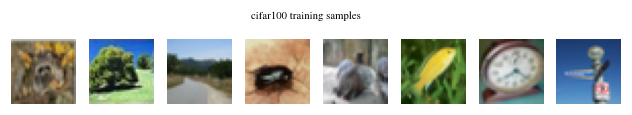

In [ ]:
dev = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
data = A.get_data(cfg, dev)
cfg.num_classes = data.num_classes
cfg.to_json(CFG_PATH)
print(f"train {len(data.xtr)} | val {len(data.xva)} | test {len(data.xte)} | classes {cfg.num_classes}")

# ---------- IEEE-style plotting defaults (single column = 3.5 in, double column = 7.16 in) ----------
IEEE_W1, IEEE_W2 = 3.5, 7.16
mpl.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman", "Times", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix", "font.size": 8, "axes.labelsize": 8, "axes.titlesize": 8, "legend.fontsize": 6.5,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "figure.dpi": 110, "savefig.dpi": 300, "axes.grid": True,
    "grid.alpha": 0.25, "grid.linewidth": 0.5, "axes.spines.top": False, "axes.spines.right": False,
    "pdf.fonttype": 42, "ps.fonttype": 42, "lines.linewidth": 1.2, "lines.markersize": 4.5, "legend.frameon": False})
# Okabe-Ito colour-blind-safe palette; families also differ by marker so figures survive greyscale printing
COL = dict(vanilla="#000000", repa="#D55E00", static="#0072B2", adaptive="#009E73")
MRK = dict(vanilla="*", repa="s", static="^", adaptive="o")
TIER_COL = {"F": "#0072B2", "R": "#E69F00", "L": "#CC79A7"}
TIER_NAME = {"F": "Full", "R": "Reduced", "L": "Lightweight"}

def savefig(fig, name):
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight"); fig.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=300)
    plt.show()

# sample images
fig, axs = plt.subplots(1, 8, figsize=(IEEE_W2, 1.0))
for i, ax in enumerate(axs):
    ax.imshow(data.xtr[i].permute(1, 2, 0).cpu().numpy()); ax.axis("off")
fig.suptitle(f"{cfg.dataset} training samples", fontsize=7, y=1.05); plt.show()

## 3 · Cost model and correctness checks (run these *before* trusting any result)

1. **RePaViT re-parameterisation is exact.** After training, the idle (activation-free) channels collapse into a single *D×D* linear map: `W_m = W2[:,idle]·W1[idle,:]`, `b_m = W2[:,idle]·b1[idle] + b2`.
2. **Sparse token dispatch ≡ dense masked computation** for the adaptive FFN (so the FLOP savings are real, not simulated).
3. **Analytic FLOPs ≡ PyTorch `FlopCounterMode`** measured on the genuine sparse execution (ratio must be 1.000), *including the estimator overhead*.

FLOPs = 2 × MACs of all linear/attention matmuls; LayerNorm, GELU and softmax are excluded (standard practice, stated in the paper).

In [ ]:
rows = []
vc = A.Cfg(**{**asdict(cfg), "dim": 96, "depth": 4, "heads": 3, "amp": False})         # small model for unit tests
torch.manual_seed(0)
xt = torch.randn(8, 3, 32, 32, device=dev)

# (1) RePaViT exactness
m = A.build_model(dict(kind="repa", theta=0.5), vc).to(dev).eval()
d = A.reparameterize_model(m).eval()
with torch.no_grad(): diff = (m(xt) - d(xt)).abs().max().item()
rows.append(("RePaViT re-parameterisation exact", f"max|Δlogit| = {diff:.2e}", diff < 1e-4))

# (2) sparse == dense, with a deliberately *mixed* random router
ad = A.build_model(dict(kind="adaptive", rho=0.6), vc).to(dev).eval()
for f in ad.adaptive_layers():
    torch.nn.init.normal_(f.est[2].weight, std=1.0); torch.nn.init.normal_(f.est[2].bias, std=1.0)
with torch.no_grad():
    o_sparse = ad(xt)
    used = ad.routing_aux()[0]["counts"].tolist()
    for f in ad.adaptive_layers(): f.dense_eval = True
    o_dense = ad(xt)
    for f in ad.adaptive_layers(): f.dense_eval = False
diff = (o_sparse - o_dense).abs().max().item()
rows.append(("Sparse dispatch == dense masked", f"max|Δ| = {diff:.2e}; tier counts L0 = {used}", diff < 1e-4))

# (3) analytic FLOPs vs torch FlopCounterMode on real execution
for nm, mod in [("vanilla", A.build_model(dict(kind="vanilla"), vc).to(dev)), ("static ρ=.5", A.build_model(dict(kind="static", rho=.5), vc).to(dev)),
                ("RePaViT θ=.5 (deployed)", d), ("adaptive (3 tiers)", ad),
                ("adaptive (2 tiers, identity-light, no attn)", A.build_model(dict(kind="adaptive", rho=.6, opts=dict(tier_set="FL", light="identity", use_attn=False)), vc).to(dev).eval())]:
    for f in mod.adaptive_layers():
        torch.nn.init.normal_(f.est[2].weight, std=1.0); torch.nn.init.normal_(f.est[2].bias, std=1.0)
    r = A.crosscheck_flops(mod, data, n=8)
    rows.append((f"FLOPs analytic vs counter — {nm}", f"counter {r['counter_G']:.5f} G | analytic {r['analytic_G']:.5f} G | ratio {r['ratio']:.4f}", abs(r["ratio"] - 1) < 5e-3))
chk = pd.DataFrame(rows, columns=["check", "result", "pass"])
display(chk)
assert chk["pass"].all(), "A correctness check failed — do not run experiments until fixed."
print("ALL CORRECTNESS CHECKS PASSED")

,check,result,pass
0,RePaViT re-parameterisation exact,max|Δlogit| = 2.83e-07,True
1,Sparse dispatch == dense masked,"max|Δ| = 2.46e-07; tier counts L0 = [520, 0, 0]",True
2,FLOPs analytic vs counter — vanilla,counter 0.06461 G | analytic 0.06461 G | ratio...,True
3,FLOPs analytic vs counter — static ρ=.5,counter 0.04544 G | analytic 0.04544 G | ratio...,True
4,FLOPs analytic vs counter — RePaViT θ=.5 (depl...,counter 0.05023 G | analytic 0.05023 G | ratio...,True
5,FLOPs analytic vs counter — adaptive (3 tiers),counter 0.04700 G | analytic 0.04700 G | ratio...,True
6,"FLOPs analytic vs counter — adaptive (2 tiers,...",counter 0.04594 G | analytic 0.04594 G | ratio...,True


ALL CORRECTNESS CHECKS PASSED


### 3.1 · Analytic cost of every configuration (before any training)
Shows how the **FFN budget is matched** across families: RePaViT-style FFN cost is `(9 − 8θ)/8` of a full FFN (activated channels + one merged *D×D* map). The adaptive model's *minimum* and *maximum* possible cost bracket what the router can express. This table needs no GPU time and goes straight into the paper's "experimental setup".

In [ ]:
def analytic_row(label, model, tc=None):
    return dict(Model=label, **{"Params (M)": A.n_params(model) / 1e6, "GFLOPs": A.flops_G(model, tc, 1)})
tmpl = []
for sp in [dict(name="vanilla", kind="vanilla")] + \
          [dict(name=f"repa_t{t:.2f}", kind="repa", theta=t) for t in (0.25, 0.5, 0.75)] + \
          [dict(name=f"static_r{r}", kind="static", rho=r) for r in (0.375, 0.625, 0.875)]:
    mdl = A.build_model(sp, cfg)
    if sp["kind"] == "repa": mdl = A.reparameterize_model(mdl)
    r = analytic_row(sp["name"], mdl)
    r["FFN cost vs full"] = {"vanilla": 1.0, "static": sp.get("rho"), "repa": (9 - 8 * sp.get("theta", 0)) / 8}[sp["kind"]]
    tmpl.append(r)
for lbl, fill in [("adaptive — all tokens Full (upper bound)", 0), ("adaptive — all tokens Lightweight (lower bound)", 2)]:
    mdl = A.build_model(dict(kind="adaptive", rho=0.5), cfg)
    L, K = len(mdl.adaptive_layers()), 3
    tc = np.zeros((L, K)); tc[:, fill] = (cfg.img_size // cfg.patch) ** 2 + 1
    r = analytic_row(lbl, mdl, tc); r["FFN cost vs full"] = A.ffn_cost_ratio(mdl, tc, 1); tmpl.append(r)
analytic = pd.DataFrame(tmpl).round(4)
display(analytic)

,Model,Params (M),GFLOPs,FFN cost vs full
0,vanilla,5.3801,0.7302,1.0000
1,repa_t0.25,4.9355,0.6727,0.8750
2,repa_t0.50,4.0484,0.5577,0.6250
3,repa_t0.75,3.1614,0.4427,0.3750
4,static_r0.375,3.1625,0.4427,0.3750
5,static_r0.625,4.0496,0.5577,0.6250
6,static_r0.875,4.9366,0.6727,0.8750
7,adaptive — all tokens Full (upper bound),5.6610,0.7379,1.0166
8,adaptive — all tokens Lightweight (lower bound),5.6610,0.3066,0.0791


## 4 · Figure 1 — the proposed architecture
Auto-generated vector figure (PDF) for the paper. A lightweight estimator reads each token (plus the CLS-attention it receives — a *free* importance signal) and emits tier logits; tokens are dispatched to Full / Reduced / Lightweight FFN paths and scattered back, so tensor shapes and the residual stream are untouched (slide 7's design constraint).

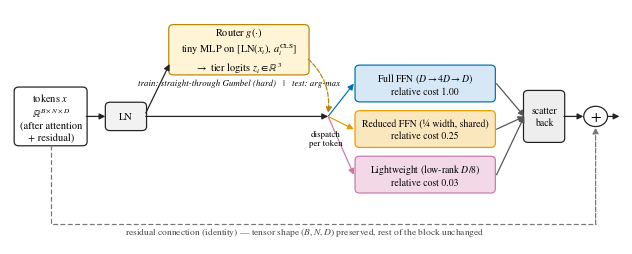

In [ ]:
from matplotlib.patches import FancyBboxPatch, Circle
def fig_architecture():
    fig, ax = plt.subplots(figsize=(IEEE_W2, 2.75)); ax.axis("off"); ax.set_xlim(0, 15.4); ax.set_ylim(-0.9, 6.0); ax.grid(False)
    def box(x, y, w, h, txt, fc="#F2F2F2", ec="#222", fs=6.8):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12", fc=fc, ec=ec, lw=.8))
        ax.text(x + w / 2, y + h / 2, txt, ha="center", va="center", fontsize=fs, linespacing=1.25)
    def arr(x1, y1, x2, y2, c="#222", ls="-", rad=0.0):
        ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-|>", lw=.8, color=c, ls=ls, shrinkA=0, shrinkB=0, connectionstyle=f"arc3,rad={rad}"))
    box(0.1, 2.0, 1.8, 1.7, "tokens $x$\n$\\mathbb{R}^{B\\times N\\times D}$\n(after attention\n+ residual)", "#FFFFFF")
    box(2.4, 2.45, 1.0, 0.8, "LN")
    box(4.0, 4.1, 3.5, 1.45, "Router $g(\\cdot)$\ntiny MLP on [LN$(x_i)$, $a_i^{\\mathrm{CLS}}$]\n$\\rightarrow$ tier logits $z_i\\in\\mathbb{R}^{3}$", "#FFF4D6", ec="#B8860B")
    ax.text(5.75, 3.78, "train: straight-through Gumbel (hard)   |   test: arg-max", ha="center", fontsize=5.8, style="italic")
    ys = [3.3, 1.95, 0.6]
    spec = [("F", "Full FFN ($D\\rightarrow 4D\\rightarrow D$)\nrelative cost 1.00"), ("R", "Reduced FFN (¼ width, shared)\nrelative cost 0.25"), ("L", "Lightweight (low-rank $D/8$)\nrelative cost 0.03")]
    sx = 8.0                                            # dispatch point
    for y, (t, s) in zip(ys, spec):
        box(8.7, y, 3.5, 1.05, s, fc={"F": "#D6E8F5", "R": "#FBE7BE", "L": "#F3D9E8"}[t], ec=TIER_COL[t], fs=6.4)
        arr(sx, 2.85, 8.65, y + 0.52, TIER_COL[t])
        arr(12.25, y + 0.52, 12.95, 2.85, "#555")
    ax.text(sx - 0.05, 2.45, "dispatch\nper token", ha="center", va="top", fontsize=5.8)
    arr(3.4, 2.85, sx, 2.85); arr(1.9, 2.85, 2.38, 2.85); arr(3.4, 2.95, 4.0, 4.4)
    arr(7.5, 4.55, sx, 2.95, "#B8860B", "--", rad=-0.25)
    box(12.95, 2.1, 1.0, 1.5, "scatter\nback", "#EEEEEE", fs=6.4)
    ax.add_patch(Circle((14.75, 2.85), 0.3, fc="white", ec="#222", lw=.8, zorder=3)); ax.text(14.75, 2.85, "+", ha="center", va="center", fontsize=10, zorder=4)
    arr(13.95, 2.85, 14.44, 2.85)
    arr(15.05, 2.85, 15.35, 2.85)
    ax.plot([1.0, 1.0, 14.75], [2.0, -0.35, -0.35], color="#777", lw=.8, ls=(0, (4, 2))); arr(14.75, -0.35, 14.75, 2.52, "#777", "--")
    ax.text(7.4, -0.65, "residual connection (identity) — tensor shape $(B,N,D)$ preserved, rest of the block unchanged", fontsize=6.2, color="#444", ha="center")
    savefig(fig, "fig1_architecture")
fig_architecture()

## 5 · Training all experiments
All runs share one recipe: AdamW, cosine schedule with warm-up, label smoothing, Mixup/CutMix, stochastic depth, fp16 AMP, grad-clip 1.0.

**How the adaptive router is trained** (`affvit.fit`, `AdaptiveFFN`)
* **Straight-through Gumbel routing** — hard one-hot assignment in the forward pass (so training sees genuine discrete tiers), soft gradient in the backward pass.
* **Budget loss** `λ·(cost − ρ)²` on the *measured* average FFN cost (estimator overhead included) pins the compute target; cost is averaged over layers, so the network is free to spend more in layers where it matters (we report where it chooses to).
* **Train/test consistency:** Gumbel noise is annealed to zero over the first 60 % of training, so the last epochs optimise *exactly* the deterministic arg-max routing used at inference. (A first prototype without this had a large train/test cost mismatch — fixed and documented here because it is a classic pitfall of learned routing.)
* **Entropy penalty** makes routing decisions confident; **CLS tokens are forced to the Full path** (ablated in §10).
* Reduced tier **shares weights** with the Full FFN (first ¼ of the hidden channels + a learnable gain) → *zero extra parameters* (ablated in §10).

In [ ]:
def _done(sp): return (RUNS / f"{sp['name']}_s{sp['seed']}" / "result.json").exists()

def _run_parallel(todo, ngpu):
    w = lambda s: 2.0 if s["kind"] == "adaptive" else 1.0
    buckets, load = [[] for _ in range(ngpu)], [0.0] * ngpu
    for s in sorted(todo, key=w, reverse=True):
        i = int(np.argmin(load)); buckets[i].append(s); load[i] += w(s)
    procs = []
    for i, b in enumerate(buckets):
        if not b: continue
        sp = WORK / f"specs_gpu{i}.json"; sp.write_text(json.dumps(b))
        lg = open(WORK / f"worker_gpu{i}.log", "a")
        env = os.environ.copy()
        env["CUDA_VISIBLE_DEVICES"] = str(i)
        p = subprocess.Popen(
            [sys.executable, "affvit.py", "--worker", "--cfg", str(CFG_PATH),
             "--specs", str(sp), "--device", "cuda:0"],
            stdout=lg, stderr=subprocess.STDOUT, cwd=str(WORK), env=env)
        procs.append((i, p, lg))
        print(f"  worker on cuda:{i}: {[s['name']+'_s'+str(s['seed']) for s in b]}")
    while any(p.poll() is None for _, p, _ in procs):
        time.sleep(15)
        for i, p, _ in procs:
            lines = [l for l in (WORK / f"worker_gpu{i}.log").read_text().splitlines() if l.strip()]
            print(f"  [gpu{i}] {lines[-1][:150] if lines else ''}")
    for i, p, lg in procs:
        lg.close()
        assert p.returncode == 0, f"worker on GPU {i} failed — see worker_gpu{i}.log"

def launch(group, seeds):
    todo = [s for s in A.make_specs(group, seeds) if not _done(s)]
    total = len(A.make_specs(group, seeds))
    print(f"=== group '{group}': {total - len(todo)}/{total} already done, {len(todo)} to run ===")
    if not todo: return

    # Train ALL models for the exact same number of epochs (cfg.epochs) to keep the comparison fair
    print(f"--- Training {len(todo)} models ({cfg.epochs} epochs) ---")
    A.run_many(todo, cfg, "cuda:0")

t0 = time.time()
for g in P["groups"]:
    launch(g, P["seeds_main"] if g == "main" else P["seeds_other"])
print(f"training stage finished in {(time.time()-t0)/60:.1f} min")

=== group 'main': 0/12 already done, 12 to run ===
--- Training 12 models (100 epochs) ---
[run ] vanilla_s0
  epoch=1 train_ce=4.314 tau=1.5 noise=1 time=17.04 lr=0.0005 val_acc=9.48 val_loss=3.989
  epoch=2 train_ce=4.051 tau=1.49 noise=0.9833 time=16.78 lr=0.001 val_acc=14.98 val_loss=3.605
  epoch=3 train_ce=3.776 tau=1.48 noise=0.9667 time=17.17 lr=0.0009997 val_acc=18.72 val_loss=3.353
  epoch=4 train_ce=3.514 tau=1.47 noise=0.95 time=17.65 lr=0.000999 val_acc=22.66 val_loss=3.137
  epoch=5 train_ce=3.473 tau=1.46 noise=0.9333 time=18.22 lr=0.0009977
  epoch=6 train_ce=3.42 tau=1.449 noise=0.9167 time=19.07 lr=0.0009959 val_acc=27.38 val_loss=2.879
  epoch=7 train_ce=3.382 tau=1.439 noise=0.9 time=20.44 lr=0.0009937
  epoch=8 train_ce=3.32 tau=1.429 noise=0.8833 time=21.13 lr=0.0009909 val_acc=29.46 val_loss=2.843
  epoch=9 train_ce=3.294 tau=1.419 noise=0.8667 time=19.9 lr=0.0009876
  epoch=10 train_ce=3.497 tau=1.409 noise=0.85 time=19.55 lr=0.0009838 val_acc=34.8 val_loss=2.62

In [ ]:
import subprocess, time
subprocess.run(["pkill", "-f", "affvit.py"])
time.sleep(3)
!nvidia-smi

Fri Nov 13 00:31:17 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   74C    P0             33W /   70W |    3201MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 6 · Efficiency benchmark (latency · throughput · peak GPU memory)
Measured with CUDA events on **real test images** (the adaptive model's routing depends on content, so synthetic inputs would be misleading), after warm-up, with the deployed (re-parameterised) RePaViT. Reported: median latency and p95 at batch 1 and 256, in fp32 and fp16 (pure `.half()` inference). Adaptive inference uses genuine sparse dispatch. **Report these even if they trail the FLOP savings** — gather/scatter overhead on small ViTs is a known limitation, and honest reporting is what makes the paper credible.

In [ ]:
def bench_all():
    names = {}
    for rf in sorted(RUNS.glob("*/result.json")):
        r = json.loads(rf.read_text()); names.setdefault(r["spec"]["name"], []).append(r["spec"]["seed"])
    for nm, seeds in names.items():
        rd = RUNS / f"{nm}_s{min(seeds)}"
        if (rd / "bench.json").exists(): continue
        m, _ = A.load_model(rd, cfg, dev)
        b = A.benchmark(m, data, dev, iters=P["bench_iters"], warm=P["bench_warm"])
        (rd / "bench.json").write_text(json.dumps(b, indent=1)); print("benchmarked", rd.name)
        del m
        if dev.type == "cuda": torch.cuda.empty_cache()
bench_all()

benchmarked adaptive_r0.625_s0
benchmarked repa_t0.50_s0
benchmarked static_r0.625_s0
benchmarked vanilla_s0


In [ ]:
import os
from pathlib import Path

# Check where cfg thinks the results are
print("cfg.out_dir is:", cfg.out_dir)
print("Does RUNS exist?", RUNS.exists())

# Look for result.json files in the default Kaggle output folder
search_path = Path("/kaggle/working/aff_results/runs")
if search_path.exists():
    print(f"\nFound {len(list(search_path.glob('*/result.json')))} result.json files in /kaggle/working/aff_results/runs")
else:
    print("\nNo results found in /kaggle/working/aff_results/runs")

# Search the whole working directory just to be sure
print("\nSearching all of /kaggle/working for result.json:")
for p in Path("/kaggle/working").rglob("result.json"):
    print(p)

cfg.out_dir is: /kaggle/working/aff_results
Does RUNS exist? True

Found 12 result.json files in /kaggle/working/aff_results/runs

Searching all of /kaggle/working for result.json:
/kaggle/working/aff_results/runs/repa_t0.50_s2/result.json
/kaggle/working/aff_results/runs/repa_t0.50_s0/result.json
/kaggle/working/aff_results/runs/repa_t0.50_s1/result.json
/kaggle/working/aff_results/runs/vanilla_s2/result.json
/kaggle/working/aff_results/runs/static_r0.625_s2/result.json
/kaggle/working/aff_results/runs/static_r0.625_s0/result.json
/kaggle/working/aff_results/runs/adaptive_r0.625_s1/result.json
/kaggle/working/aff_results/runs/vanilla_s1/result.json
/kaggle/working/aff_results/runs/adaptive_r0.625_s0/result.json
/kaggle/working/aff_results/runs/adaptive_r0.625_s2/result.json
/kaggle/working/aff_results/runs/vanilla_s0/result.json
/kaggle/working/aff_results/runs/static_r0.625_s1/result.json


## 7 · Results — tables
`collect()` gathers every run into one dataframe. Table I is the headline comparison at the **matched FFN budget** (mean ± std over seeds); `ΔFLOPs` is relative to the vanilla ViT, so the efficiency/accuracy trade can be read off directly.

In [ ]:
def pretty(sp):
    n, k = sp["name"], sp["kind"]
    if n.startswith("abl_"):
        return {"abl_2tier_FL": "2 tiers: Full+Light", "abl_2tier_FR": "2 tiers: Full+Reduced", "abl_noshare": "No weight sharing (separate reduced FFN)",
                "abl_light_identity": "Light path = skip (no compute)", "abl_no_cls_attn": "Router w/o CLS-attention feature",
                "abl_cls_not_forced": "CLS token not forced to Full"}[n]
    pre = "+KD " if sp.get("kd") else ""
    return pre + {"vanilla": "Vanilla ViT", "static": f"Static narrow FFN (ρ={sp.get('rho')})", "repa": f"RePaViT-style (θ={sp.get('theta')})",
                  "adaptive": f"Token-Adaptive FFN (ρ={sp.get('rho')})"}[k]

def group_of(n): return "ablation" if n.startswith("abl_") else ("kd" if n.startswith("kd_") else "core")

def collect():
    rows = []
    for rf in sorted(RUNS.glob("*/result.json")):
        r = json.loads(rf.read_text()); sp = r["spec"]
        row = dict(run=rf.parent.name, name=sp["name"], label=pretty(sp), kind=sp["kind"], group=group_of(sp["name"]), seed=sp["seed"],
                   top1=r["test_acc1"], top5=r["test_acc5"], val1=r["val_acc1"], params_M=r["params"] / 1e6, gflops=r["flops_G"],
                   train_min=r["train_time_s"] / 60,
                   ffn_cost={"vanilla": 1.0, "static": sp.get("rho"), "repa": (9 - 8 * sp.get("theta", 0)) / 8}.get(sp["kind"], r.get("ffn_cost_ratio")))
        pf = rf.parent / "test_preds.npy"      # P/R/F1 for EVERY run (incl. older runs) from saved test predictions
        if pf.exists():
            from sklearn.metrics import precision_recall_fscore_support as _prfs
            _p, _r, _f, _ = _prfs(data.yte.cpu().numpy(), np.load(pf).astype(np.int64), average="macro", zero_division=0)
            row.update(test_prec=100 * _p, test_rec=100 * _r, test_f1=100 * _f)
        bf = rf.parent / "bench.json"
        if bf.exists(): row.update(json.loads(bf.read_text()))
        rows.append(row)
    return pd.DataFrame(rows)

raw = collect()
metric_cols = [c for c in raw.columns if c not in ("run", "name", "label", "kind", "group", "seed")]
agg = raw.groupby(["name", "label", "kind", "group"], sort=False)[metric_cols].agg(["mean", "std"]).reset_index()
agg.columns = ["_".join([c for c in col if c]).strip("_") for col in agg.columns]
agg["n_seeds"] = raw.groupby("name", sort=False).size().values
raw.to_csv(TAB / "all_runs_raw.csv", index=False); agg.to_csv(TAB / "all_runs_aggregated.csv", index=False)

prec = "fp16" if "lat_bs256_fp16_ms_median" in raw.columns else "fp32"
LAT256 = f"lat_bs256_{prec}_ms_median"
base = agg[agg.name == "vanilla"].iloc[0] if (agg.name == "vanilla").any() else None

def pm(m, s, d=2): return f"{m:.{d}f}" if (pd.isna(s) or s == 0) else f"{m:.{d}f} ± {s:.{d}f}"
def sp_rho(n):
    return n.split("_r")[1] if "_r" in n else None
def make_table(sel, with_delta=True, with_bench=True):
    out = []
    for _, r in agg[sel].iterrows():
        row = {"Model": r["label"], "Top-1 (%)": pm(r["top1_mean"], r["top1_std"]), "Top-5 (%)": pm(r["top5_mean"], r["top5_std"]),
               "Prec. (%)": pm(r["test_prec_mean"], r["test_prec_std"]), "Rec. (%)": pm(r["test_rec_mean"], r["test_rec_std"]), "F1 (%)": pm(r["test_f1_mean"], r["test_f1_std"]),
               "Params (M)": f"{r['params_M_mean']:.2f}", "GFLOPs": f"{r['gflops_mean']:.3f}", "FFN cost": f"{r['ffn_cost_mean']:.3f}"}
        if with_delta and base is not None:
            row["ΔFLOPs (%)"] = f"{100*(r['gflops_mean']/base['gflops_mean']-1):+.1f}"
            row["ΔTop-1"] = f"{r['top1_mean']-base['top1_mean']:+.2f}"
            static_row = agg[agg.name == f"static_r{sp_rho(r['name'])}"]
            if len(static_row) and not r["name"].startswith("static"):
                row["ΔFLOPs vs static"] = f"{100*(r['gflops_mean']/static_row.iloc[0]['gflops_mean']-1):+.1f}"
        if with_bench and f"{LAT256}_mean" in r and not pd.isna(r.get(f"{LAT256}_mean")):
            row[f"Lat. bs1 (ms)"] = f"{r[f'lat_bs1_{prec}_ms_median_mean']:.2f}"
            row[f"Lat. bs256 (ms/img)"] = f"{r[f'{LAT256}_mean']/256:.3f}"
            row["Thr. (img/s)"] = f"{r[f'thr_bs256_{prec}_ips_mean']:.0f}"
            if f"mem_bs256_{prec}_MB_mean" in r: row["Peak mem (MB)"] = f"{r[f'mem_bs256_{prec}_MB_mean']:.0f}"
        row["#seeds"] = int(r["n_seeds"]); out.append(row)
    return pd.DataFrame(out)

def esc(s):
    s = str(s)
    for a, b in [("&", r"\&"), ("%", r"\%"), ("_", r"\_"), ("#", r"\#"), ("±", r"$\pm$"), ("θ", r"$\theta$"), ("ρ", r"$\rho$"), ("Δ", r"$\Delta$"), ("→", r"$\to$")]:
        s = s.replace(a, b)
    return s

def to_latex(df, caption, label, name):
    cols = list(df.columns)
    L = [r"\begin{table*}[t]" if len(cols) > 7 else r"\begin{table}[t]", r"\centering", rf"\caption{{{caption}}}", rf"\label{{{label}}}", r"\footnotesize",
         rf"\begin{{tabular}}{{l{'c' * (len(cols) - 1)}}}", r"\toprule", " & ".join(esc(c) for c in cols) + r" \\", r"\midrule"]
    for _, r in df.iterrows(): L.append(" & ".join(esc(v) for v in r.values) + r" \\")
    L += [r"\bottomrule", r"\end{tabular}", r"\end{table*}" if len(cols) > 7 else r"\end{table}"]
    (TAB / f"{name}.tex").write_text("\n".join(L)); return "\n".join(L)

core = agg.group == "core"
T1 = make_table(core & agg.name.isin(["vanilla", "repa_t0.50", "static_r0.625", "adaptive_r0.625"]))
print("TABLE I — headline comparison at matched FFN budget"); display(T1)
to_latex(T1, "Comparison at a matched FFN budget (mean $\\pm$ std over seeds). FLOPs include the router overhead.", "tab:main", "table1_main")
T2 = make_table(core)
print("TABLE II — full Pareto sweep (all budgets)"); display(T2)
to_latex(T2, "Accuracy--efficiency sweep over FFN budgets.", "tab:sweep", "table2_sweep")

TABLE I — headline comparison at matched FFN budget


,Model,Top-1 (%),Top-5 (%),Prec. (%),Rec. (%),F1 (%),Params (M),GFLOPs,FFN cost,ΔFLOPs (%),ΔTop-1,ΔFLOPs vs static,Lat. bs1 (ms),Lat. bs256 (ms/img),Thr. (img/s),Peak mem (MB),#seeds
0,Token-Adaptive FFN (ρ=0.625),57.88 ± 0.50,80.58 ± 0.23,57.58 ± 0.60,57.88 ± 0.50,57.52 ± 0.56,5.66,0.558,0.625,-23.6,-0.45,-0.0,21.20,0.143,6989,504,3
1,RePaViT-style (θ=0.5),57.17 ± 0.66,80.53 ± 0.28,56.79 ± 0.67,57.17 ± 0.66,56.75 ± 0.66,4.05,0.558,0.625,-23.6,-1.17,NaN,4.98,0.100,9990,449,3
2,Static narrow FFN (ρ=0.625),58.50 ± 0.20,81.01 ± 0.33,58.11 ± 0.15,58.50 ± 0.20,58.11 ± 0.17,4.05,0.558,0.625,-23.6,+0.17,NaN,4.29,0.100,9963,455,3
3,Vanilla ViT,58.33 ± 0.22,80.70 ± 0.22,57.91 ± 0.17,58.33 ± 0.22,57.89 ± 0.16,5.38,0.730,1.000,+0.0,+0.00,NaN,4.53,0.122,8204,481,3


TABLE II — full Pareto sweep (all budgets)


,Model,Top-1 (%),Top-5 (%),Prec. (%),Rec. (%),F1 (%),Params (M),GFLOPs,FFN cost,ΔFLOPs (%),ΔTop-1,ΔFLOPs vs static,Lat. bs1 (ms),Lat. bs256 (ms/img),Thr. (img/s),Peak mem (MB),#seeds
0,Token-Adaptive FFN (ρ=0.625),57.88 ± 0.50,80.58 ± 0.23,57.58 ± 0.60,57.88 ± 0.50,57.52 ± 0.56,5.66,0.558,0.625,-23.6,-0.45,-0.0,21.20,0.143,6989,504,3
1,RePaViT-style (θ=0.5),57.17 ± 0.66,80.53 ± 0.28,56.79 ± 0.67,57.17 ± 0.66,56.75 ± 0.66,4.05,0.558,0.625,-23.6,-1.17,NaN,4.98,0.100,9990,449,3
2,Static narrow FFN (ρ=0.625),58.50 ± 0.20,81.01 ± 0.33,58.11 ± 0.15,58.50 ± 0.20,58.11 ± 0.17,4.05,0.558,0.625,-23.6,+0.17,NaN,4.29,0.100,9963,455,3
3,Vanilla ViT,58.33 ± 0.22,80.70 ± 0.22,57.91 ± 0.17,58.33 ± 0.22,57.89 ± 0.16,5.38,0.730,1.000,+0.0,+0.00,NaN,4.53,0.122,8204,481,3


'\\begin{table*}[t]\n\\centering\n\\caption{Accuracy--efficiency sweep over FFN budgets.}\n\\label{tab:sweep}\n\\footnotesize\n\\begin{tabular}{lcccccccccccccccc}\n\\toprule\nModel & Top-1 (\\%) & Top-5 (\\%) & Prec. (\\%) & Rec. (\\%) & F1 (\\%) & Params (M) & GFLOPs & FFN cost & $\\Delta$FLOPs (\\%) & $\\Delta$Top-1 & $\\Delta$FLOPs vs static & Lat. bs1 (ms) & Lat. bs256 (ms/img) & Thr. (img/s) & Peak mem (MB) & \\#seeds \\\\\n\\midrule\nToken-Adaptive FFN ($\\rho$=0.625) & 57.88 $\\pm$ 0.50 & 80.58 $\\pm$ 0.23 & 57.58 $\\pm$ 0.60 & 57.88 $\\pm$ 0.50 & 57.52 $\\pm$ 0.56 & 5.66 & 0.558 & 0.625 & -23.6 & -0.45 & -0.0 & 21.20 & 0.143 & 6989 & 504 & 3 \\\\\nRePaViT-style ($\\theta$=0.5) & 57.17 $\\pm$ 0.66 & 80.53 $\\pm$ 0.28 & 56.79 $\\pm$ 0.67 & 57.17 $\\pm$ 0.66 & 56.75 $\\pm$ 0.66 & 4.05 & 0.558 & 0.625 & -23.6 & -1.17 & nan & 4.98 & 0.100 & 9990 & 449 & 3 \\\\\nStatic narrow FFN ($\\rho$=0.625) & 58.50 $\\pm$ 0.20 & 81.01 $\\pm$ 0.33 & 58.11 $\\pm$ 0.15 & 58.50 $\\pm$ 0.20 & 58.11 $

## 8 · Figure 2 — accuracy–efficiency Pareto frontier (the paper's central claim)
defines success as *a favourable shift of the Pareto frontier*, not raw accuracy. Panel (a): Top-1 vs **analytic GFLOPs** (hardware-independent). Panel (b): Top-1 vs **measured latency** (what a practitioner experiences). Error bars are std over seeds where available. Dashed grey = empirical Pareto frontier of all models.

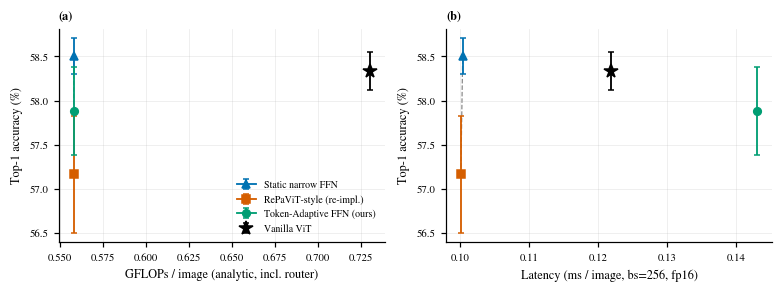

In [ ]:
def pareto_front(pts):            # pts: list of (cost, acc); keep points not dominated (lower cost & higher acc)
    pts = sorted(pts); best, front = -1e9, []
    for c, a in pts:
        if a > best: front.append((c, a)); best = a
    return front

def fig_pareto():
    d = agg[agg.group == "core"]
    xs = [("gflops", "GFLOPs / image (analytic, incl. router)")]
    if f"{LAT256}_mean" in d.columns and d[f"{LAT256}_mean"].notna().any(): xs.append((LAT256, f"Latency (ms / image, bs=256, {prec})"))
    fig, axs = plt.subplots(1, len(xs), figsize=(IEEE_W2 if len(xs) > 1 else IEEE_W1, 2.7), squeeze=False)
    for ax, (xc, xl) in zip(axs[0], xs):
        scale = 1 / 256 if xc == LAT256 else 1
        allpts = []
        for fam, lab in [("static", "Static narrow FFN"), ("repa", "RePaViT-style (re-impl.)"), ("adaptive", "Token-Adaptive FFN (ours)")]:
            s = d[d.kind == fam].sort_values(f"{xc}_mean")
            if s.empty: continue
            x, y = s[f"{xc}_mean"] * scale, s["top1_mean"]
            ax.errorbar(x, y, yerr=s["top1_std"].fillna(0), fmt=MRK[fam] + "-", color=COL[fam], label=lab, capsize=2, lw=1.2, ms=5)
            allpts += list(zip(x, y))
        v = d[d.kind == "vanilla"]
        if not v.empty:
            ax.errorbar(v[f"{xc}_mean"] * scale, v["top1_mean"], yerr=v["top1_std"].fillna(0), fmt="*", color="k", ms=9, label="Vanilla ViT", capsize=2)
            allpts += list(zip(v[f"{xc}_mean"] * scale, v["top1_mean"]))
        if len(allpts) > 2:
            fr = pareto_front(allpts); ax.plot(*zip(*fr), "--", color="#888", lw=.8, zorder=0)
        ax.set_xlabel(xl); ax.set_ylabel("Top-1 accuracy (%)")
    axs[0][0].legend(loc="lower right")
    for i, ax in enumerate(axs[0]): ax.set_title(f"({'ab'[i]})", loc="left", fontweight="bold")
    fig.tight_layout(); savefig(fig, "fig2_pareto")
fig_pareto()

## 9 · Figure 3–6 — *how* the model allocates computation


* **Fig 3** — where in depth the network spends compute (tier mix per layer).
* **Fig 4** — spatial routing maps: which image regions receive full compute (images ordered by total compute).
* **Fig 5** — (a) do *uncertain* images receive more compute (slide 6's "importance and/or uncertainty")? (b) does token compute track CLS-attention importance? (c) compute distribution of correctly vs. incorrectly classified images.
* **Fig 6** — training dynamics: validation accuracy and the budget converging to its target.

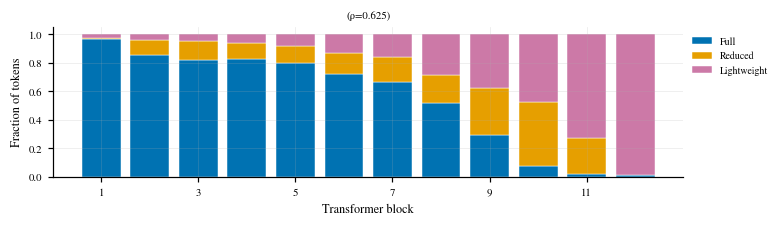

In [ ]:
def fig_tiers():
    ad = agg[(agg.kind == "adaptive") & (agg.group == "core")].sort_values("name")
    if ad.empty: return
    fig, axs = plt.subplots(1, len(ad), figsize=(IEEE_W2, 2.1), squeeze=False, sharey=True)
    for ax, (_, r) in zip(axs[0], ad.iterrows()):
        fr = np.mean([np.array(json.loads(rf.read_text())["tier_frac_per_layer"]) for rf in RUNS.glob(f"{r['name']}_s*/result.json")], 0)
        L, K = fr.shape; tiers = A.build_model(dict(kind="adaptive", rho=.5), cfg).adaptive_layers()[0].tiers
        bot = np.zeros(L)
        for k in range(K):
            ax.bar(np.arange(1, L + 1), fr[:, k], bottom=bot, color=TIER_COL[tiers[k]], label=TIER_NAME[tiers[k]], width=.8, edgecolor="white", lw=.3); bot += fr[:, k]
        ax.set_title(r["label"].replace("Token-Adaptive FFN ", ""), fontsize=7); ax.set_xlabel("Transformer block"); ax.set_xticks(np.arange(1, L + 1, 2))
    axs[0][0].set_ylabel("Fraction of tokens"); axs[0][-1].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
    fig.tight_layout(); savefig(fig, "fig3_tiers_per_layer")
fig_tiers()

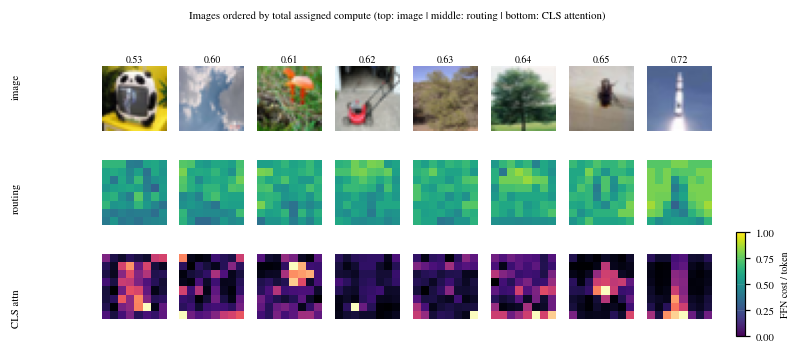

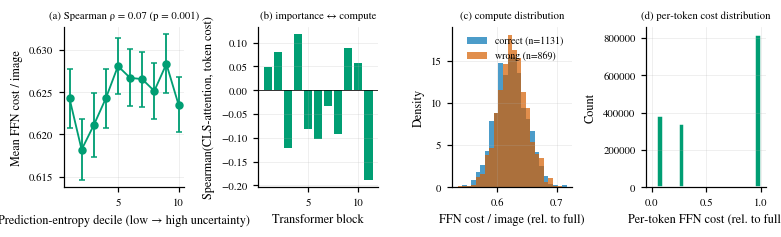

{
 "spearman_cost_vs_entropy": 0.07137271836665805,
 "p": 0.0014033396028810376,
 "mean_cost_correct": 0.6234734654426575,
 "mean_cost_wrong": 0.6261143684387207,
 "mannwhitney_p": 0.016892572800097934,
 "per_layer_spearman_attn": [
  0.048040226941700424,
  0.08044808858431002,
  -0.1224165117005461,
  0.11702071501555054,
  -0.08153406053491137,
  -0.10231894200876704,
  -0.03278338157936646,
  -0.09262667169634514,
  0.08899591177260455,
  0.05662395689928504,
  -0.18887653661681988,
  NaN
 ],
 "image_cost_mean": 0.6246209144592285,
 "image_cost_std": 0.025145642459392548,
 "image_cost_min": 0.5341496467590332,
 "image_cost_max": 0.7161207795143127,
 "per_token_cost_mean": 0.6018946766853333,
 "per_token_cost_std": 0.4287821650505066,
 "per_token_cost_min": 0.0625,
 "per_token_cost_max": 1.0,
 "per_layer_cost_min": 0.07692307978868484,
 "per_layer_cost_max": 0.978405773639679,
 "per_l


In [ ]:
MAIN_AD = "adaptive_r0.625"
def get_analysis(name=MAIN_AD, seed=0, n=P["n_analysis"]):
    rd = RUNS / f"{name}_s{seed}"
    if not (rd / "result.json").exists(): return None, None
    m, res = A.load_model(rd, cfg, dev)
    return m, A.analyze_routing(m, data, n=n, bs=250)

model_ad, an = get_analysis()
if an is not None:
    cpath = an["c_path"]; cost = cpath[an["assign"]]                   # (n, L, T) relative cost of every token in every layer
    img_cost = cost.mean((1, 2)) + an["c_est"]                          # per-image FFN cost (incl. router)
    g = cfg.img_size // cfg.patch

    # ---------------- Fig 4: spatial routing maps ----------------------------------------------------------
    def fig_maps(k=8):
        tok = cost[:, :, 1:].mean(1).reshape(-1, g, g)
        attn_map = an["attn"][:, :, 1:].mean(1).reshape(-1, g, g)   # v2 fix: drop CLS token before reshape if an["attn"] is not None else None
        order = np.argsort(img_cost); pick = order[np.linspace(0, len(order) - 1, k).astype(int)]
        nrows = 3 if attn_map is not None else 2
        fig, axs = plt.subplots(nrows, k, figsize=(IEEE_W2, 0.65 * nrows + 1.2))
        for j, i in enumerate(pick):
            axs[0, j].imshow(data.xte[i].permute(1, 2, 0).cpu().numpy()); axs[0, j].axis("off")
            axs[0, j].set_title(f"{img_cost[i]:.2f}", fontsize=6.5, pad=2)
            im = axs[1, j].imshow(tok[i], cmap="viridis", vmin=0, vmax=1, interpolation="nearest"); axs[1, j].axis("off")
            if nrows == 3:
                axs[2, j].imshow(attn_map[i], cmap="magma", interpolation="nearest"); axs[2, j].axis("off")
        cax = fig.add_axes([0.93, 0.08, 0.012, 0.30]); fig.colorbar(im, cax=cax).set_label("FFN cost / token", fontsize=6.5)
        fig.text(0.01, 0.80, "image", rotation=90, fontsize=7, va="center")
        fig.text(0.01, 0.48, "routing", rotation=90, fontsize=7, va="center")
        if nrows == 3: fig.text(0.01, 0.16, "CLS attn", rotation=90, fontsize=7, va="center")
        fig.suptitle("Images ordered by total assigned compute (top: image | middle: routing | bottom: CLS attention)",
                     fontsize=7, y=1.02)
        savefig(fig, "fig4_routing_maps")
    fig_maps()

    # ---------------- Fig 5: uncertainty / importance / distribution ------------------------------------
    ent, cor = an["entropy"], an["correct"]
    rho_u, p_u = stats.spearmanr(img_cost, ent)
    srho = [stats.spearmanr(an["attn"][:, l, 1:].ravel()[::7].astype(np.float32), cost[:, l, 1:].ravel()[::7])[0] for l in range(cost.shape[1])]
    fig, axs = plt.subplots(1, 4, figsize=(IEEE_W2, 2.2))
    q = np.quantile(ent, np.linspace(0, 1, 11)); b = np.clip(np.digitize(ent, q[1:-1]), 0, 9)
    mu = np.array([img_cost[b == i].mean() for i in range(10)]); se = np.array([img_cost[b == i].std() / np.sqrt((b == i).sum()) for i in range(10)])
    axs[0].errorbar(np.arange(1, 11), mu, yerr=1.96 * se, fmt="o-", color=COL["adaptive"], capsize=2)
    axs[0].set(xlabel="Prediction-entropy decile (low → high uncertainty)", ylabel="Mean FFN cost / image"); axs[0].set_title(f"(a) Spearman ρ = {rho_u:.2f} (p = {p_u:.1g})", fontsize=7)
    axs[1].bar(np.arange(1, len(srho) + 1), srho, color=COL["adaptive"]); axs[1].axhline(0, color="k", lw=.5)
    axs[1].set(xlabel="Transformer block", ylabel="Spearman(CLS-attention, token cost)"); axs[1].set_title("(b) importance ↔ compute", fontsize=7)
    bins = np.linspace(img_cost.min(), img_cost.max(), 25)
    axs[2].hist(img_cost[cor], bins, alpha=.7, color="#0072B2", label=f"correct (n={cor.sum()})", density=True)
    axs[2].hist(img_cost[~cor], bins, alpha=.7, color="#D55E00", label=f"wrong (n={(~cor).sum()})", density=True)
    axs[2].set(xlabel="FFN cost / image (rel. to full)", ylabel="Density"); axs[2].legend(); axs[2].set_title("(c) compute distribution", fontsize=7)
    per_tok = cost[:, :, 1:].reshape(-1)
    axs[3].hist(per_tok, bins=np.arange(0, 1.05, 0.05), color=COL["adaptive"], edgecolor="white", lw=.3)
    axs[3].set(xlabel="Per-token FFN cost (rel. to full)", ylabel="Count")
    axs[3].set_title("(d) per-token cost distribution", fontsize=7)
    fig.tight_layout(); savefig(fig, "fig5_allocation_analysis")
    mw = stats.mannwhitneyu(img_cost[~cor], img_cost[cor], alternative="two-sided") if (~cor).any() and cor.any() else None
    summary_alloc = dict(spearman_cost_vs_entropy=float(rho_u), p=float(p_u), mean_cost_correct=float(img_cost[cor].mean()),
                         mean_cost_wrong=float(img_cost[~cor].mean()) if (~cor).any() else None,
                         mannwhitney_p=float(mw.pvalue) if mw else None, per_layer_spearman_attn=[float(x) for x in srho],
                         image_cost_mean=float(img_cost.mean()), image_cost_std=float(img_cost.std()),
                         image_cost_min=float(img_cost.min()), image_cost_max=float(img_cost.max()))
    summary_alloc["per_token_cost_mean"] = float(per_tok.mean())
    summary_alloc["per_token_cost_std"]  = float(per_tok.std())
    summary_alloc["per_token_cost_min"]  = float(per_tok.min())
    summary_alloc["per_token_cost_max"]  = float(per_tok.max())
    per_layer_cost = cost.mean(0).mean(-1)
    summary_alloc["per_layer_cost_min"] = float(per_layer_cost.min())
    summary_alloc["per_layer_cost_max"] = float(per_layer_cost.max())
    summary_alloc["per_layer_cost_std"] = float(per_layer_cost.std())
    (TAB / "allocation_analysis.json").write_text(json.dumps(summary_alloc, indent=1)); print(json.dumps(summary_alloc, indent=1)[:900])
else:
    print("adaptive main run not found — run the 'main' group first")

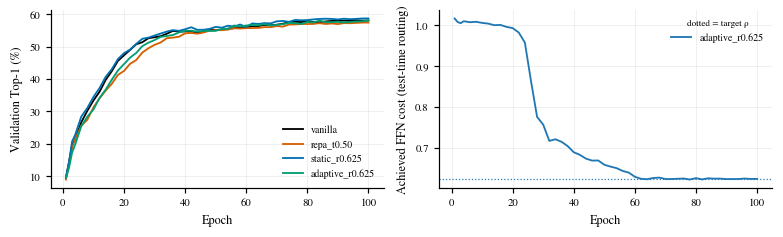

In [ ]:
def fig_curves():
    fig, axs = plt.subplots(1, 2, figsize=(IEEE_W2, 2.2))
    for nm, fam in [("vanilla", "vanilla"), ("repa_t0.50", "repa"), ("static_r0.625", "static"), ("adaptive_r0.625", "adaptive")]:
        hs = [json.loads(rf.read_text())["history"] for rf in RUNS.glob(f"{nm}_s*/result.json")]
        if not hs: continue
        ep = [h["epoch"] for h in hs[0] if "val_acc" in h]
        va = np.mean([[h["val_acc"] for h in hh if "val_acc" in h] for hh in hs], 0)
        axs[0].plot(ep, va, color=COL[fam], label=nm, marker=None)
    axs[0].set(xlabel="Epoch", ylabel="Validation Top-1 (%)"); axs[0].legend()
    for nm in ["adaptive_r0.375", "adaptive_r0.625", "adaptive_r0.875"]:
        hs = [json.loads(rf.read_text())["history"] for rf in RUNS.glob(f"{nm}_s*/result.json")]
        if not hs: continue
        ep = [h["epoch"] for h in hs[0] if "val_cost" in h]; vc_ = np.mean([[h["val_cost"] for h in hh if "val_cost" in h] for hh in hs], 0)
        l, = axs[1].plot(ep, vc_, label=nm); axs[1].axhline(float(nm.split("_r")[1]), color=l.get_color(), ls=":", lw=.8)
    axs[1].set(xlabel="Epoch", ylabel="Achieved FFN cost (test-time routing)"); axs[1].legend(title="dotted = target ρ", title_fontsize=6)
    fig.tight_layout(); savefig(fig, "fig6_training_dynamics")
fig_curves()

In [ ]:
# --- 11.1 Cross-seed routing stability ---
stability = None
seeds_for_stab = sorted({json.loads(rf.read_text())["spec"]["seed"]
                         for rf in RUNS.glob(f"{MAIN_AD}_s*/result.json")})
if len(seeds_for_stab) >= 2:
    models = []
    for s in seeds_for_stab:
        m, _ = A.load_model(RUNS / f"{MAIN_AD}_s{s}", cfg, dev)
        models.append(m)
    stability = A.routing_stability(models, data, n=P["n_analysis"], bs=250)
    (TAB / "routing_stability.json").write_text(json.dumps(stability, indent=1))
    print(f"cross-seed routing stability (mean over seeds & layers): {stability['mean_off_diag']:.3f}")
    print("  per-layer mean:", [f"{v:.3f}" for v in stability["per_layer_mean_off_diag"]])
    print("  (chance = 1/K =", 1/len(models[0].adaptive_layers()[0].tiers), ")")
    for m in models: del m
    if dev.type == "cuda": torch.cuda.empty_cache()
else:
    print("need ≥ 2 seeds of adaptive_r0.625 to compute routing stability — run `fast`/`paper` main group")

cross-seed routing stability (mean over seeds & layers): 0.670
  per-layer mean: ['0.942', '0.743', '0.686', '0.741', '0.685', '0.594', '0.560', '0.517', '0.407', '0.531', '0.634', '1.000']
  (chance = 1/K = 0.3333333333333333 )


In [ ]:
# --- 11.2 Wall-clock breakdown ---
if model_ad is not None:
    wb = A.time_breakdown(model_ad, data, dev, bs=256, iters=30, warm=10)
    (TAB / "wallclock_breakdown.json").write_text(json.dumps(wb, indent=1))
    print(json.dumps(wb, indent=1))
    if wb.get("dispatch_pct") is not None:
        print(f"→ dispatch overhead: {wb['dispatch_overhead_ms']:.2f} ms "
              f"({wb['dispatch_pct']:.1f}% of forward) at bs=256")
else:
    print("run the adaptive main group first")

{
 "total_ms": 91.20425796508789,
 "dense_ms": 138.8932647705078,
 "sparse_ms": 93.39416122436523,
 "dispatch_overhead_ms": -45.49910354614258,
 "dispatch_pct": -49.88703878667506
}
→ dispatch overhead: -45.50 ms (-49.9% of forward) at bs=256


## 10 · Ablations and diagnostics (do the design choices matter?)
**A. Eval-time routing-policy ablation** (no retraining). Take the *trained* adaptive model and replace its learned router by: *random* routing with the **same per-image tier budget**, a **non-learned CLS-attention heuristic** (top-attention tokens → Full) at the same budget, a **feature-norm heuristic**, and an **inverted** router (swaps Full ↔ Lightweight). If the learned estimator is genuinely informative: learned ≫ random, and learned ≥ heuristics. Inverted should collapse. *(This is a diagnostic on the test split, not used for model selection.)*

**B. Training ablations** (group `ablation`, ρ = 0.625): number of tiers, weight sharing, lightweight-path type, router inputs, CLS handling.

**C. Knowledge distillation** (group `kd`): the same vanilla-teacher distillation applied to *every* efficient model, so the fairness of §7 is preserved.

TABLE III — eval-time routing-policy ablation


,Routing policy,Top-1 (%),Top-5 (%),GFLOPs,FFN cost
0,Learned router (ours),57.45,80.47,0.557,0.624
1,Random (same per-image budget),57.71,80.20,0.557,0.624
2,CLS-attention heuristic,57.43,80.04,0.557,0.624
3,Token-norm heuristic,57.51,79.90,0.558,0.626
4,Inverted router (diagnostic),5.75,19.75,0.409,0.302


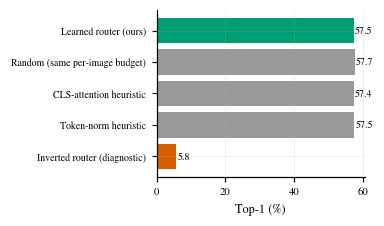

In [ ]:
POL = [(None, "Learned router (ours)"), ("shuffle", "Random (same per-image budget)"), ("attn", "CLS-attention heuristic"),
       ("norm", "Token-norm heuristic"), ("invert", "Inverted router (diagnostic)")]
pol_rows = []
if model_ad is not None:
    for pol, lab in POL:
        r = A.eval_with_policy(model_ad, data, pol, "test")
        pol_rows.append({"Routing policy": lab, "Top-1 (%)": f"{r['acc1']:.2f}", "Top-5 (%)": f"{r['acc5']:.2f}", "GFLOPs": f"{r['flops_G']:.3f}",
                         "FFN cost": f"{A.ffn_cost_ratio(model_ad, r['counts'], r['n']):.3f}"})
    T_pol = pd.DataFrame(pol_rows); print("TABLE III — eval-time routing-policy ablation"); display(T_pol)
    to_latex(T_pol, "Replacing the learned router at test time (same trained weights). Random/heuristic policies keep each image's tier budget.", "tab:policy", "table3_policy")
    fig, ax = plt.subplots(figsize=(IEEE_W1, 2.1))
    acc = [float(r["Top-1 (%)"]) for r in pol_rows]
    ax.barh(range(len(acc)), acc, color=[COL["adaptive"]] + ["#999"] * (len(acc) - 2) + ["#D55E00"]); ax.set_yticks(range(len(acc)))
    ax.set_yticklabels([l for _, l in POL], fontsize=6.5); ax.invert_yaxis(); ax.set_xlabel("Top-1 (%)")
    for i, a in enumerate(acc): ax.text(a + .3, i, f"{a:.1f}", va="center", fontsize=6.5)
    fig.tight_layout(); savefig(fig, "fig7_policy_ablation")

abl = agg[(agg.group == "ablation")]
if not abl.empty and (agg.name == MAIN_AD).any():
    ref = agg[agg.name == MAIN_AD].iloc[0]
    rows_ = [dict(Variant="Full method (3 tiers, shared, low-rank light, CLS-attn, CLS→Full)", **{"Top-1 (%)": pm(ref.top1_mean, ref.top1_std), "GFLOPs": f"{ref.gflops_mean:.3f}", "FFN cost": f"{ref.ffn_cost_mean:.3f}", "ΔTop-1": "—", "Params (M)": f"{ref.params_M_mean:.2f}"})]
    for _, r in abl.iterrows():
        rows_.append({"Variant": r["label"], "Top-1 (%)": pm(r.top1_mean, r.top1_std), "GFLOPs": f"{r.gflops_mean:.3f}", "FFN cost": f"{r.ffn_cost_mean:.3f}", "ΔTop-1": f"{r.top1_mean-ref.top1_mean:+.2f}", "Params (M)": f"{r.params_M_mean:.2f}"})
    T_abl = pd.DataFrame(rows_); print("TABLE IV — training ablations (ρ=0.625)"); display(T_abl)
    to_latex(T_abl, "Ablation of the Token-Adaptive FFN design choices at $\\rho=0.625$.", "tab:abl", "table4_ablation")

kd = agg[(agg.group == "kd")]
if not kd.empty:
    T_kd = make_table((agg.group == "kd") | agg.name.isin(["vanilla", "repa_t0.50", "static_r0.625", "adaptive_r0.625"]), with_bench=False)
    print("TABLE V — effect of distillation from the vanilla teacher (applied to all efficient models)"); display(T_kd)
    to_latex(T_kd, "Distilling every efficient model from the same vanilla teacher.", "tab:kd", "table5_kd")

## 11 · Statistical significance
With 3 seeds, claims must be tested, not eyeballed. For the headline matched-budget comparison we report (i) **Welch's t-test** across seeds, (ii) **exact McNemar test** on paired test-set predictions (per seed), and (iii) a **paired bootstrap 95 % CI** for the Top-1 difference. *With few seeds, treat p-values as supporting evidence and rely on effect size + CI.* Differences in achieved GFLOPs are printed so a reader can judge whether the budgets really match; the Pareto sweep (Fig 2) is the more robust evidence.

In [ ]:
def preds(name, seed): return np.load(RUNS / f"{name}_s{seed}" / "test_preds.npy")
ytest = data.yte.cpu().numpy()

def mcnemar(pa, pb, y):
    a, b = pa == y, pb == y
    n_ab, n_ba = int((a & ~b).sum()), int((~a & b).sum())
    p = stats.binomtest(min(n_ab, n_ba), n_ab + n_ba, 0.5).pvalue if n_ab + n_ba else 1.0
    return n_ab, n_ba, p

def boot_diff(pa, pb, y, B=2000):
    rs = np.random.RandomState(0); n = len(y); ca, cb = (pa == y).astype(float), (pb == y).astype(float)
    d = [100 * (ca[i].mean() - cb[i].mean()) for i in (rs.randint(0, n, n) for _ in range(B))]
    return np.percentile(d, [2.5, 97.5])

stat_rows = []
if (raw.name == MAIN_AD).any():
    for other, lab in [("repa_t0.50", "RePaViT-style (θ=0.5)"), ("static_r0.625", "Static narrow FFN (ρ=0.625)"), ("vanilla", "Vanilla ViT")]:
        if not (raw.name == other).any(): continue
        sa, so = sorted(raw[raw.name == MAIN_AD].seed), sorted(raw[raw.name == other].seed)
        common = [s for s in sa if s in so]
        a = raw[raw.name == MAIN_AD].top1.values; b = raw[raw.name == other].top1.values
        wp = stats.ttest_ind(a, b, equal_var=False).pvalue if len(a) > 1 and len(b) > 1 else np.nan
        mn = [mcnemar(preds(MAIN_AD, s), preds(other, s), ytest) for s in common]
        lo, hi = boot_diff(preds(MAIN_AD, common[0]), preds(other, common[0]), ytest)
        ga, gb = raw[raw.name == MAIN_AD].gflops.mean(), raw[raw.name == other].gflops.mean()
        stat_rows.append({"Adaptive vs": lab, "Δ Top-1 (pp)": f"{a.mean()-b.mean():+.2f}", "95% bootstrap CI (seed 0)": f"[{lo:+.2f}, {hi:+.2f}]",
                          "Welch p": "n/a (1 seed)" if np.isnan(wp) else f"{wp:.3g}", "McNemar p (per seed)": ", ".join(f"{m[2]:.2g}" for m in mn),
                          "Δ GFLOPs (%)": f"{100*(ga/gb-1):+.1f}"})
    T_stat = pd.DataFrame(stat_rows); print("TABLE VI — significance of Token-Adaptive (ρ=0.625) vs. baselines"); display(T_stat)
    to_latex(T_stat, "Statistical comparison of the Token-Adaptive FFN against each baseline.", "tab:stats", "table6_stats")
else:
    print("run the main group first")

TABLE VI — significance of Token-Adaptive (ρ=0.625) vs. baselines


,Adaptive vs,Δ Top-1 (pp),95% bootstrap CI (seed 0),Welch p,McNemar p (per seed),Δ GFLOPs (%)
0,RePaViT-style (θ=0.5),+0.71,"[-0.04, +1.57]",0.216,"0.071, 0.04, 0.23",-0.0
1,Static narrow FFN (ρ=0.625),-0.62,"[-1.97, -0.37]",0.152,"0.0049, 0.22, 0.68",-0.0
2,Vanilla ViT,-0.45,"[-1.76, -0.16]",0.254,"0.022, 0.44, 0.89",-23.6


## 12 · Export everything

In [ ]:
env = dict(python=platform.python_version(), torch=torch.__version__, cuda=torch.version.cuda, numpy=np.__version__, pandas=pd.__version__,
           gpus=[torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())], profile=PROFILE, config=asdict(cfg),
           note="FLOPs = 2*MACs of linear+attention matmuls (LN/GELU/softmax excluded); verified against torch FlopCounterMode.")
(Path(cfg.out_dir) / "environment_and_config.json").write_text(json.dumps(env, indent=1))

lines = [f"# Results summary (profile={PROFILE}, dataset={cfg.dataset}, epochs={cfg.epochs})",
         "", "## Headline comparison (Table I)", "", T1.to_markdown(index=False) if hasattr(T1, "to_markdown") else T1.to_string(index=False)]
for tt, tt_name in [(T2, "Table II — Pareto sweep"), (T_stat, "Table VI — significance")]:
    if tt is not None:
        lines += ["", f"## {tt_name}", "", tt.to_markdown(index=False) if hasattr(tt, "to_markdown") else tt.to_string(index=False)]
if (TAB / "allocation_analysis.json").exists():
    lines += ["", "## Allocation analysis", "", (TAB / "allocation_analysis.json").read_text()]
if (TAB / "routing_stability.json").exists():
    lines += ["", "## Cross-seed routing stability", "", (TAB / "routing_stability.json").read_text()]
if (TAB / "wallclock_breakdown.json").exists():
    lines += ["", "## Wall-clock breakdown", "", (TAB / "wallclock_breakdown.json").read_text()]
(Path(cfg.out_dir) / "RESULTS_SUMMARY.md").write_text("\n".join(lines))

zp = WORK / "aff_paper_artifacts"
if zp.with_suffix(".zip").exists(): zp.with_suffix(".zip").unlink()
stage = WORK / "_stage"; shutil.rmtree(stage, ignore_errors=True); stage.mkdir()
for sub in ("figures", "tables"): shutil.copytree(Path(cfg.out_dir) / sub, stage / sub)
for f in ("environment_and_config.json", "RESULTS_SUMMARY.md"): shutil.copy(Path(cfg.out_dir) / f, stage / f)
(stage / "runs").mkdir()
for rd in RUNS.glob("*"):                       # keep metrics/predictions, drop heavy weights
    (stage / "runs" / rd.name).mkdir()
    for f in rd.glob("*"):
        if f.suffix != ".pt": shutil.copy(f, stage / "runs" / rd.name / f.name)
shutil.copy(WORK / "affvit.py", stage / "affvit.py")
shutil.make_archive(str(zp), "zip", stage); shutil.rmtree(stage)
print("written:", zp.with_suffix(".zip"), f"({zp.with_suffix('.zip').stat().st_size/2**20:.1f} MB)")
print("figures:", sorted(p.name for p in FIG.glob("*.pdf")))
print("tables :", sorted(p.name for p in TAB.glob("*.tex")))

written: /kaggle/working/aff_paper_artifacts.zip (0.9 MB)
figures: ['fig1_architecture.pdf', 'fig2_pareto.pdf', 'fig3_tiers_per_layer.pdf', 'fig4_routing_maps.pdf', 'fig5_allocation_analysis.pdf', 'fig6_training_dynamics.pdf', 'fig7_policy_ablation.pdf']
tables : ['table1_main.tex', 'table2_sweep.tex', 'table3_policy.tex', 'table6_stats.tex']


## 13 · From notebook

**title.** *Token-Adaptive Feedforward Networks: Input-Dependent Computation Allocation for Efficient Vision Transformers*


1. **Introduction** — FFN dominates ViT cost (slide 3); structural reductions (RePaViT) are input-independent (slide 5); contribution list below.
2. **Related work** — *verify each citation yourself before submitting.* Token pruning / merging (e.g., DynamicViT, ToMe, A-ViT), block/depth routing (e.g., AdaViT, Mixture-of-Depths), conditional computation / mixture-of-experts (Shazeer et al.; Switch Transformer), slimmable/nested networks, and the Gumbel-softmax / straight-through estimator (Jang et al.; Bengio et al.), plus the RePaViT reference exactly as in your slides: Xu, Li, Chen, Liu & Wang, *RePaViT*, ICML 2025 (PMLR 267:69363–69376).
3. **Method** — Fig 1; estimator; three tiers; ST-Gumbel training; budget loss; noise annealing; sparse inference; cost model (state FLOP convention).
4. **Experimental setup** — Table (§3.1), identical recipe, matched budgets, seeds, hardware.
5. **Results** — Table I, Fig 2 (Pareto), latency/throughput/memory honestly, Table II.
6. **Analysis** — Fig 3–5, Table III (random/heuristic/inverted router), Table IV (ablations), Table V (distillation), Table VI (statistics).
7. **Limitations & conclusion.**

**Contribution**
* A token-level, three-tier adaptive FFN whose router is trained end-to-end under an explicit compute budget (estimator cost included).
* An iso-budget comparison protocol against a re-implemented channel-idle/re-parameterised FFN *and* a static-narrow control.
* Evidence (Figs 3–5, Table III) on *whether and how* the router allocates compute.

---

## v2 additions

- **§Ablation / Table IV** — add `abl_perlayer_static` as the FIRST ablation row. This control isolates per-token adaptivity from per-layer adaptivity. If its accuracy matches `adaptive_r0.625` at matched FLOPs, then per-token routing is not responsible for any gain — this is a finding, not a failure, and should be reported honestly.
- **§Ablation** — add `abl_no_budget`, `abl_lam5`, `abl_lam500` as a sub-table titled "effect of the budget-loss weight". `abl_no_budget` gives the upper bound of the adaptive architecture without a compute penalty.
- **§Ablation** — add `abl_heavy_router` and state whether its accuracy gain exceeds its FLOP overhead.
- **§Results** — Table I now has a `ΔFLOPs vs static` column so the reader can see the comparison is at ACHIEVED, not nominal, budget. If the gap exceeds 3%, interpolate a static model at the adaptive FLOPs or state so explicitly.
- **§Analysis — Fig 4** now has a CLS-attention row so the reader can see WHAT the router selected.
- **§Analysis — Fig 5(d)** adds the per-token compute distribution required by slide 10's "compute distribution across tokens" metric.
- **§Analysis** — new subsection "cross-seed routing stability" using `routing_stability.json`. State chance = 1/K = 33.3%. Stability > 0.5 = strong signal.
- **§Results** — Fig 1 (Methods) can now state `flop_breakdown` numbers: "of the vanilla ViT's X GFLOPs, Y are FFN and Z are attention".
- **§Limitations** — quote `wallclock_breakdown.json`: "at bs=256, dispatch overhead adds X.XX ms (Y.Y% of forward)".
- **§Experimental Setup** — add: "we do not perform test-set model selection; the last-epoch checkpoint is evaluated on the test split exactly once". Add `cudnn.benchmark=False, cudnn.deterministic=True` to reproducibility. Report `dataset_hash`.
- **PROFILE choice** — `fast` is now paper-grade for `main` (3 seeds), but `sweep`, `ablation`, `kd` still use 1 seed. State this explicitly: "main results use 3 seeds; sweep/ablation/distillation use 1 seed and should be read as trends."